## Hydrodynamic model of the Southern North Sea

In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import mikeio
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import modelskill as ms
import torch

# dataset helper
from helper import get_altimetry_obs, get_wl_point_obs
from helper import plot_shred_reconstruction, extract_water_level_measurements, align_ds

import sys
from pathlib import Path

# Add parent directory to path to access src module
sys.path.insert(0, str(Path.cwd().parent.parent))

# Importing modules from src
from src.datamanager import ROMDataManager
from src.engine import SHREDEngine
from src.train import fit, evaluate
from src.mSHRED.mSRED import mSHRED
from src.utils import plot_training_curves, evaluate_model

np.random.seed(0)

# get device
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

## Load Data and Measurement

In [3]:
# folders
dfs_fldr = "datasets/output/Area.dfsu"
msh_fldr = "datasets/input/Mesh_8000_elems_HD_v2.mesh"
obs_fldr  = "datasets/observations/"

msh = mikeio.open(msh_fldr)
dfs = mikeio.open(dfs_fldr)

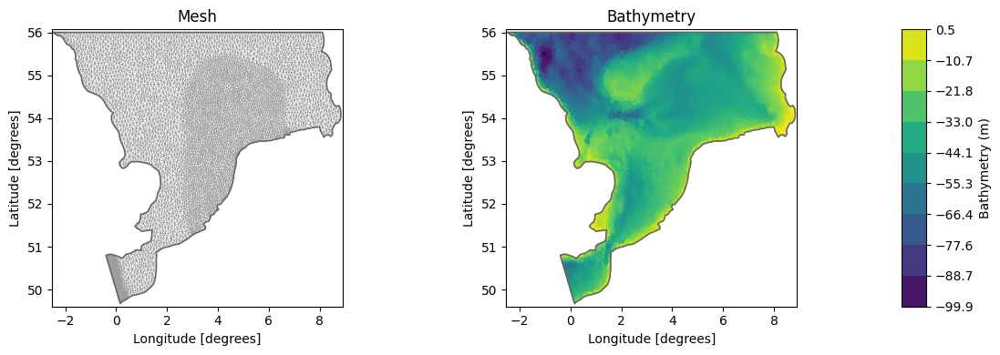

In [4]:
# plot geometry
geom = dfs.geometry

fig, axs = plt.subplots(1,2, figsize = (12,4))
geom.plot.mesh(ax=axs[0])
geom.plot(ax=axs[1])
plt.tight_layout()
plt.show()

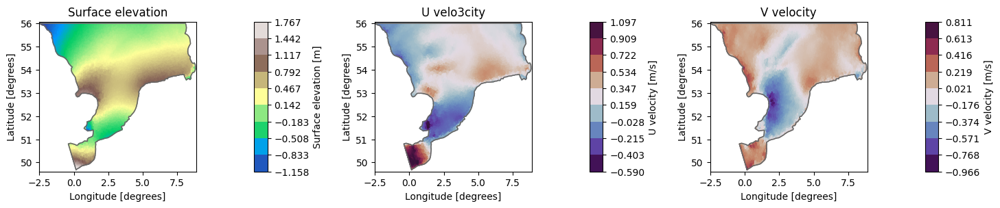

In [5]:
# plot a simulation
ds = dfs.read()

dsH = ds["Surface elevation"]
dsU = ds["U velocity"]
dsV = ds["V velocity"]

plot_time = ds.time[-1]
fig,axs = plt.subplots(1, 3, figsize=(15,5))
dsH.sel(time=plot_time).plot(ax=axs[0], title="Surface elevation", cmap = "terrain")
dsU.sel(time=plot_time).plot(ax=axs[1], title="U velo3city", cmap = "twilight_shifted")
dsV.sel(time=plot_time).plot(ax=axs[2], title="V velocity", cmap = "twilight_shifted")
plt.tight_layout()
plt.show()

del dfs

## Available Sensors

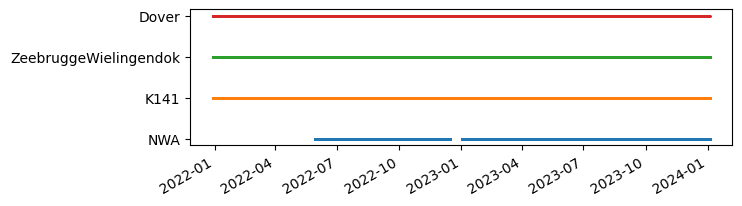

In [6]:
# sensor coverage

wllist = get_wl_point_obs()      # get water level point observations
#altlist = get_altimetry_obs()   # get altimetry observations (not used in this example, but can be included for training)

# high fidelity observations 
high_fidelity = ["Dover", "ZeebruggeWielingendok", "NWA", "K141"]

# combine all observations and filter for high fidelity ones
alllist = wllist #+ altlist

alllist = [obs for obs in alllist if obs.name in high_fidelity]   # filter for high fidelity observations (optional, can be used to focus on specific sensors)

#plot temporal coverage of observations
ms.plotting.temporal_coverage(alllist)
plt.show()

del wllist #, altlist

Total stations: 4
Stations with full temporal coverage: 1
Intermittent stations: 3


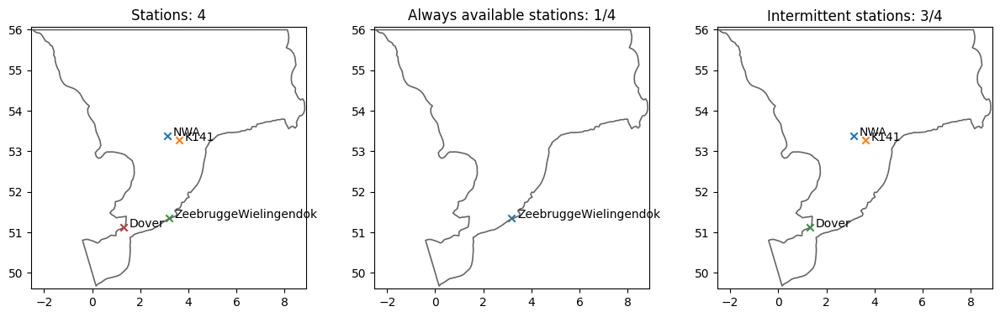

In [7]:
# Select stations with full temporal coverage

stations = []
available_stations = []
intermittent = []
for i in range(len(alllist)):
    stations.append(alllist[i])
    if ds.time.isin(alllist[i].time).all():
        available_stations.append(alllist[i])
    else:
        intermittent.append(alllist[i])

print(f"Total stations: {len(stations)}")
print(f"Stations with full temporal coverage: {len(available_stations)}")
print(f"Intermittent stations: {len(intermittent)}")

fig, axs = plt.subplots(1,3, figsize = (12,4))
ms.plotting.spatial_overview(stations, mod = msh.geometry, figsize = (5,5), ax=axs[0], title=f"Stations: {len(stations)}")
ms.plotting.spatial_overview(available_stations, mod = msh.geometry, figsize = (5,5), ax=axs[1], title=f"Always available stations: {len(available_stations)}/{len(stations)}")
ms.plotting.spatial_overview(intermittent, mod = msh.geometry, figsize = (5,5), ax=axs[2], title=f"Intermittent stations: {len(intermittent)}/{len(stations)}")

plt.tight_layout()
plt.show()


In [8]:
# Extract water level measurements
measurements = extract_water_level_measurements(stations, ds_time=ds.time, obs_fldr=obs_fldr)

In [9]:
# Extract the values and convert to torch tensors

# remove nans from H, U, V 
dsH = dsH.values[:,~np.isnan(ds["Surface elevation"].values).any(axis=0)]
dsU = dsU.values[:,~np.isnan(ds["Surface elevation"].values).any(axis=0)]
dsV = dsV.values[:,~np.isnan(ds["Surface elevation"].values).any(axis=0)]

# outputs
H = torch.tensor(dsH, dtype=torch.float32)
U = torch.tensor(dsU, dtype=torch.float32)
V = torch.tensor(dsV, dtype=torch.float32)

# inputs
measurements = torch.tensor(measurements, dtype=torch.float32)

# print the shape of the arrays
print("H shape:", H.shape)
print("U shape:", U.shape)
print("V shape:", V.shape)
print("Measurements shape:", measurements.shape)

# free memory
del dsH, dsU, dsV

H shape: torch.Size([35039, 8532])
U shape: torch.Size([35039, 8532])
V shape: torch.Size([35039, 8532])
Measurements shape: torch.Size([35039, 4])


In [10]:
# Extract measurements for always-available stations only
av_indices = [stations.index(s) for s in available_stations]
measurements_av = measurements[:, av_indices]

time_steps, _ = measurements_av.shape

# Count NaNs for intermittent stations
intermittent_indices = [stations.index(s) for s in intermittent]
nan_counts_intermittent = np.isnan(measurements[:, intermittent_indices].numpy()).sum(axis=0)

# Build a clean coverage table and sort by coverage percentage
rows = []
for i, s in enumerate(intermittent):
    ok_count = int(time_steps - nan_counts_intermittent[i])
    nan_count = int(nan_counts_intermittent[i])
    coverage = 100 * ok_count / time_steps
    rows.append({
        "station": s.name,
        "ok": ok_count,
        "nans": nan_count,
        "coverage_%": round(coverage, 1),
    })
coverage_df = pd.DataFrame(rows).sort_values("coverage_%", ascending=False).reset_index(drop=True)

print(f"Intermittent stations ({len(intermittent)}):")
display(coverage_df.style.format({"ok": "{:,}", "nans": "{:,}", "coverage_%": "{:.1f}"}))

Intermittent stations (3):


,station,ok,nans,coverage_%
0,K141,"34,972",67,99.8
1,NWA,"26,469","8,570",75.5
2,Dover,"17,024","18,015",48.6


## ROM training: split the full trajectory by months

2 random month for valid, 3 random month for testing

In [11]:
# Assuming 30 days per month, 24 hours per day, and measurements every 30 minutes (2 per hour)
lenmonths = (30 * 24 * 2)  
nmonths = H.shape[0] // lenmonths 
ntime_keeped = nmonths * lenmonths 
print(f"Time keeprd: {ntime_keeped}/{H.shape[0]} total steps ({nmonths} months) -> coverage: {100*ntime_keeped/H.shape[0]:.1f}% \n")

# reshape the arrays to (nmonths, lenmonths, nfeatures) for training
H = H[:ntime_keeped].reshape(nmonths, lenmonths, -1)
U = U[:ntime_keeped].reshape(nmonths, lenmonths, -1)
V = V[:ntime_keeped].reshape(nmonths, lenmonths, -1)
measurements = measurements[:ntime_keeped].reshape(nmonths, lenmonths, -1)
measurements_av = measurements_av[:ntime_keeped].reshape(nmonths, lenmonths, -1)    

print("Reshaped H shape:", H.shape)
print("Reshaped U shape:", U.shape)
print("Reshaped V shape:", V.shape)
print("Reshaped measurements shape:", measurements.shape)
print("Reshaped measurements shape:", measurements_av.shape)

#permute the months 
permuted_indices = np.random.permutation(nmonths)
H = H[permuted_indices]
U = U[permuted_indices]
V = V[permuted_indices]
measurements = measurements[permuted_indices]
measurements_av = measurements_av[permuted_indices]

print("\npermutation indices:", permuted_indices)

Time keeprd: 34560/35039 total steps (24 months) -> coverage: 98.6% 

Reshaped H shape: torch.Size([24, 1440, 8532])
Reshaped U shape: torch.Size([24, 1440, 8532])
Reshaped V shape: torch.Size([24, 1440, 8532])
Reshaped measurements shape: torch.Size([24, 1440, 4])
Reshaped measurements shape: torch.Size([24, 1440, 1])

permutation indices: [11 10 22 14 20  1 13 23 16  8  6 17  4  2  5 18  9  7 19  3  0 21 15 12]


## Hyperparameters

In [12]:
ERRORS = []

# DataManager
LAGS = 48               # number of past time steps to use as input for the model (e.g., 48 for 24 hours of data at 30-minute intervals)

TRAIN_SIZE = 0.8        # percentage of data used for training 
VAL_SIZE = 0.1          # percentage of data used for validation
TEST_SIZE = 0.1         # percentage of data used for testing

COMPRESS_H = 12         # modes kept for H (surface elevation)
COMPRESS_U = 40         # modes kept for U (U velocity)
COMPRESS_V = 68         # modes kept for V (V velocity)

# Training
OPTIMIZER = "AdamW"     # optimizer to use
LEARNING_RATE = 1e-3    # learning rate for training
NUM_EPOCHS = 200        # maximum number of epochs for training
LR_SCHEDULER = "CosineAnnealingLR"      # learning rate scheduler to use
SCHEDULER_STEP_SIZE = NUM_EPOCHS        # step size for learning rate scheduler (if applicable)

BATCH_SIZE = 32         # batch size for training
PATIENCE = 40           # number of epochs with no improvement on validation loss before stopping training
VERBOSE_TRAIN = True

# Architecture
ENCODER_DEPTH = 2              # number of encoder layers
HIDDEN_SIZE = 32                # hidden size for encoder and decoder layers
N_HEADS = 4                     # number of attention heads (if using a transformer-based architecture)
DIM_FEEDFORWARD = 48            # dimension of feedforward network in transformer (if using a transformer-based architecture)
DECODER = "cnn"                 # type of decoder to use (mpl or cnn)   
DECODER_HIDDEN_SIZES = [64]     # hidden sizes for decoder layers 
DROPOUT = 0.0                   # dropout rate for encoder and decoder layers
MASKING_TYPE = "mask_data"      # type of masking to apply to inputs during training (mask_data, mask_data_random, etc.)

## (T.0): only available sensors

In [13]:
# Keep only sensors that never contain NaNs over trajectories and time
nan_sensor_mask = torch.isnan(measurements).any(dim=(0,1))
measurements_av = measurements[:, :, ~nan_sensor_mask]

kept_sensor_indices = torch.where(~nan_sensor_mask)[0]
removed_sensor_indices = torch.where(nan_sensor_mask)[0]

# print the shape of the arrays
print("\nAfter selecting always-available stations only:")
print("H shape:", H.shape)
print("U shape:", U.shape)
print("V shape:", V.shape)
print("Measurements shape:", measurements_av.shape)


After selecting always-available stations only:
H shape: torch.Size([24, 1440, 8532])
U shape: torch.Size([24, 1440, 8532])
V shape: torch.Size([24, 1440, 8532])
Measurements shape: torch.Size([24, 1440, 1])


In [14]:
# Data manager
manager = ROMDataManager(lags=LAGS, train_size=TRAIN_SIZE, val_size=VAL_SIZE, test_size=TEST_SIZE)
# add data to manager
manager.add_data(H, id = "Surface elevation" , compress = COMPRESS_H, measurements = measurements_av)
manager.add_data(U, id = "U velocity", compress = COMPRESS_U)
manager.add_data(V, id = "V velocity", compress = COMPRESS_V)
# prepare datasets
train_dataset, val_dataset, test_dataset = manager.prepare(verbose = True)

# network input and output shapes
nn_input_shape = train_dataset[0][0].shape[1] 
nn_output_shape = train_dataset[0][1].shape[0]  
print("\nInput shape for the model:", nn_input_shape)
print("Output shape for the model:", nn_output_shape)

Nuber of nan values in measurements after imputation: 0
Residual energy of Surface elevation after keeping 12 modes: 0.1755 %
Residual energy of U velocity after keeping 40 modes: 0.1998 %
Residual energy of V velocity after keeping 68 modes: 0.1932 %

Datasets: ['Surface elevation', 'U velocity', 'V velocity']

Number of nan values in sensor measurements after masking: 0

Data shapes after preparation:
Train:	 torch.Size([27360, 48, 1]) -> torch.Size([27360, 120])
Val:	 torch.Size([2880, 48, 1]) -> torch.Size([2880, 120])
Test:	 torch.Size([4320, 48, 1]) -> torch.Size([4320, 120])

Input shape for the model: 1
Output shape for the model: 120


Starting training...


Training:  38%|███▊      | 77/200 [09:04<14:30,  7.07s/it, Train Loss=0.00391, Val Loss=0.00464, Patience=39, Best Val Loss=0.00444, LR=6.69e-04]

Early stopping at epoch 78
Training completed with best validation loss: 0.0044


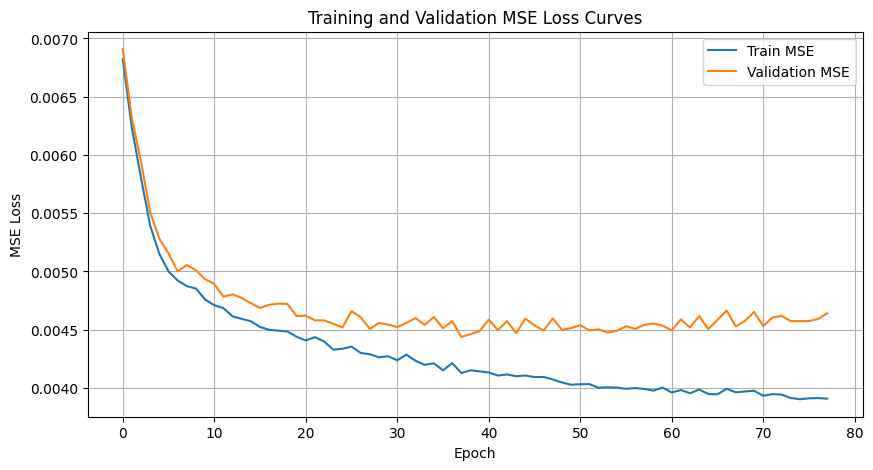

,model,type,train-mse,val-mse,test-mse,train-mre,val-mre,test-mre
0,(mSHRED): TR+cnn,(T.0): always-available stations only,0.004128,0.004438,0.006931,0.127817,0.135475,0.164078


In [15]:
# mSHRED TRAINING
model_args = dict(
    # Encoder
    encoder="transformer", encoder_depth=ENCODER_DEPTH, input_size=nn_input_shape, n_heads=N_HEADS,
    dim_feedforward=DIM_FEEDFORWARD, hidden_size=HIDDEN_SIZE, input_length=LAGS, double_channels = False,
    # Decoder
    decoder=DECODER, decoder_hidden_sizes=DECODER_HIDDEN_SIZES, output_size=nn_output_shape, dropout=DROPOUT,
)
mshred = mSHRED(args=model_args).to(device)

# Use cosine annealing LR schedule
train_errors, valid_errors = fit(
    mshred, train_dataset, val_dataset,
    optimizer=OPTIMIZER, lr=LEARNING_RATE, num_epochs=NUM_EPOCHS, patience=PATIENCE, verbose=VERBOSE_TRAIN,
    lr_scheduler=LR_SCHEDULER, scheduler_step_size=SCHEDULER_STEP_SIZE,
)

# PLOT TRAINING CURVES
plot_training_curves(train_errors, valid_errors)

# EVALUATION
test_error = evaluate_model(
    evaluate, mshred, train_dataset, val_dataset, test_dataset, 
    model = f"(mSHRED): TR+{DECODER}", type="(T.0): always-available stations only"
)

ERRORS.append(test_error)
dataframe_errors = pd.DataFrame(ERRORS)
display(dataframe_errors)
dataframe_errors.to_csv("dataframe_errors.csv", index=False)

Saved plot: /home/matteo/Documents/Masked-SHRED/Notebooks/HYDRO/outputs/shred_(T.0)_always-available_stations_only.png


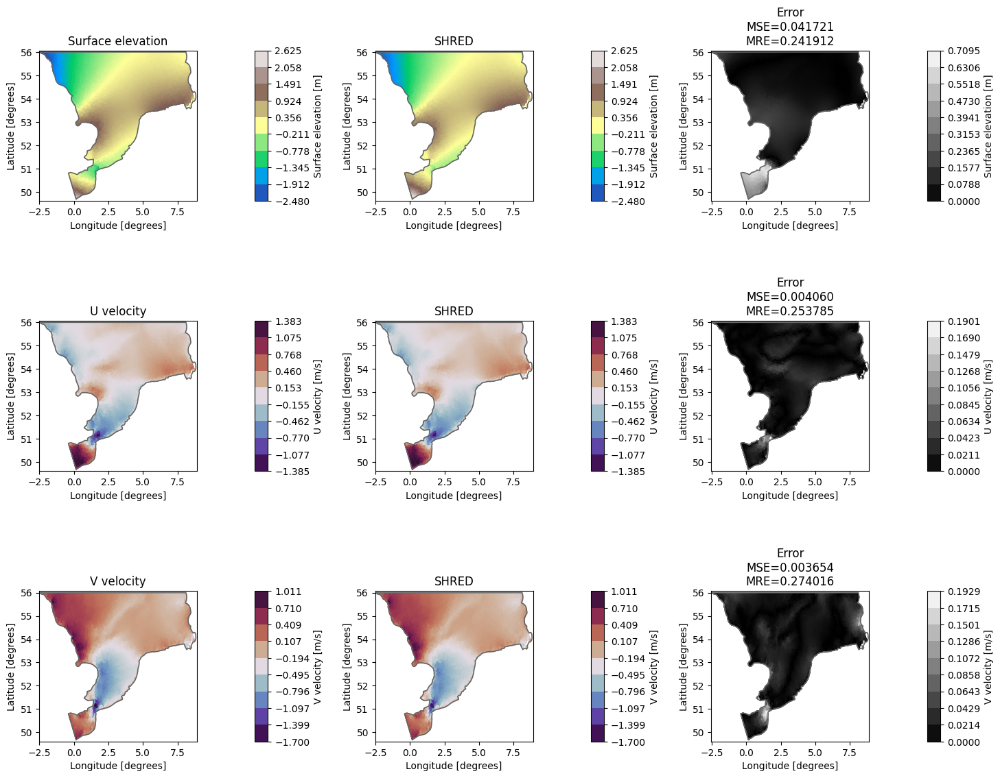

In [16]:
# mSHRED RECONSTRUCTION
engine = SHREDEngine(manager, mshred)
test_reconstruction = engine.sensor_to_reconstruction_dataset(test_dataset)
ds_r = align_ds(manager.test_indices, ds, permuted_indices, lenmonths, geom)
ds_shred, ds_error = plot_shred_reconstruction(test_reconstruction, ds_r, geom, title_suffix="(T.0)_always-available_stations_only")

del engine, test_reconstruction, ds_shred, ds_error, mshred, model_args, train_errors, valid_errors, test_error, kept_sensor_indices, removed_sensor_indices, ds_r

## (S.0): only available sensors

Starting training...


Training:  46%|████▋     | 93/200 [06:06<07:01,  3.94s/it, Train Loss=0.00390, Val Loss=0.00458, Patience=39, Best Val Loss=0.00441, LR=5.47e-04]

Early stopping at epoch 94
Training completed with best validation loss: 0.0044


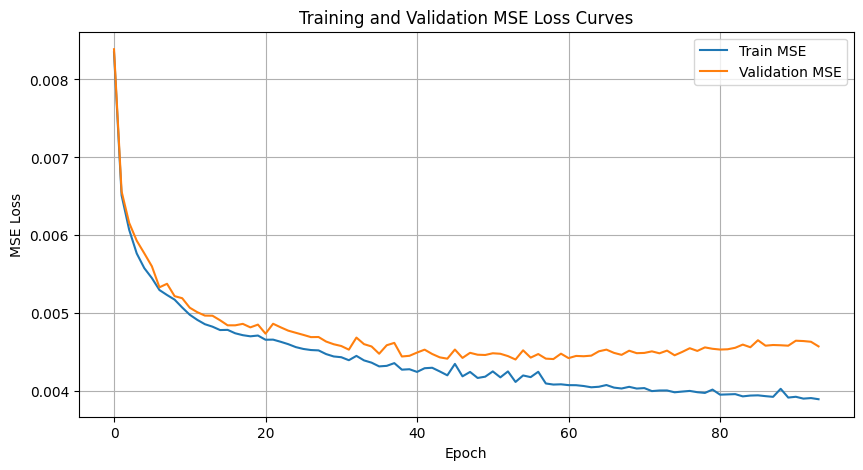

,model,type,train-mse,val-mse,test-mse,train-mre,val-mre,test-mre
0,(mSHRED): TR+cnn,(T.0): always-available stations only,0.004128,0.004438,0.006931,0.127817,0.135475,0.164078
1,(mSHRED): LSTM+cnn,(S.0): always-available stations only,0.004119,0.004407,0.007174,0.127691,0.134495,0.165759


In [17]:
# mSHRED TRAINING
model_args = dict(
    # Encoder
    encoder="lstm", input_size=nn_input_shape, hidden_size=HIDDEN_SIZE, num_layers=ENCODER_DEPTH,
    # Decoder
    decoder=DECODER, decoder_hidden_sizes=DECODER_HIDDEN_SIZES, output_size=nn_output_shape, dropout=DROPOUT,
)
mshred = mSHRED(args=model_args).to(device)

# Use cosine annealing LR schedule
train_errors, valid_errors = fit(
    mshred, train_dataset, val_dataset,
    optimizer=OPTIMIZER, lr=LEARNING_RATE, num_epochs=NUM_EPOCHS, patience=PATIENCE, verbose=VERBOSE_TRAIN,
    lr_scheduler=LR_SCHEDULER, scheduler_step_size=SCHEDULER_STEP_SIZE,
)

# PLOT TRAINING CURVES
plot_training_curves(train_errors, valid_errors)

# EVALUATION
test_error = evaluate_model(
    evaluate, mshred, train_dataset, val_dataset, test_dataset, 
    model = f"(mSHRED): LSTM+{DECODER}", type="(S.0): always-available stations only"
)

ERRORS.append(test_error)
dataframe_errors = pd.DataFrame(ERRORS)
display(dataframe_errors)

Saved plot: /home/matteo/Documents/Masked-SHRED/Notebooks/HYDRO/outputs/shred_(S.0)_always-available_stations_only.png


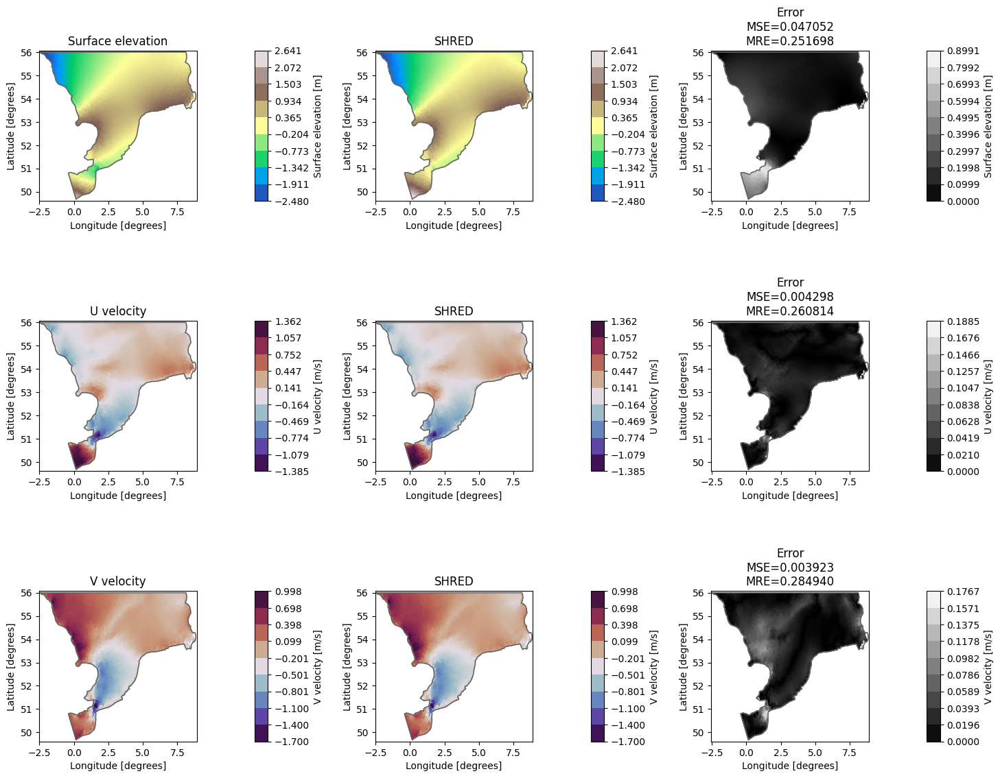

In [18]:
# SHRED RECONSTRUCTION 
engine_shred = SHREDEngine(manager, mshred)
test_reconstruction_shred = engine_shred.sensor_to_reconstruction_dataset(test_dataset)
ds_r = align_ds(manager.test_indices, ds, permuted_indices, lenmonths, geom)
ds_shred, ds_error = plot_shred_reconstruction(test_reconstruction_shred, ds_r, geom, title_suffix="(S.0)_always-available_stations_only")

del engine_shred, test_reconstruction_shred, ds_shred, ds_error, mshred, manager, train_dataset, val_dataset, test_dataset, model_args, train_errors, valid_errors, test_error, nn_input_shape, nn_output_shape

## (T.1.A): Median imputer

In [19]:
# Data manager
manager = ROMDataManager(lags=LAGS, train_size=TRAIN_SIZE, val_size=VAL_SIZE, test_size=TEST_SIZE)
# add data to manager
manager.add_data(H, id="Surface elevation", compress=COMPRESS_H, measurements=measurements, imputer="median")
manager.add_data(U, id="U velocity", compress=COMPRESS_U)
manager.add_data(V, id="V velocity", compress=COMPRESS_V)
# prepare datasets
train_dataset, val_dataset, test_dataset = manager.prepare(verbose=True)

# network input and output shapes
nn_input_shape = train_dataset[0][0].shape[1]
nn_output_shape = train_dataset[0][1].shape[0]
print("\nInput shape for the model:", nn_input_shape)
print("Output shape for the model:", nn_output_shape)

Nuber of nan values in measurements after imputation: 0
Residual energy of Surface elevation after keeping 12 modes: 0.1755 %
Residual energy of U velocity after keeping 40 modes: 0.1998 %
Residual energy of V velocity after keeping 68 modes: 0.1932 %

Datasets: ['Surface elevation', 'U velocity', 'V velocity']

Number of nan values in sensor measurements after masking: 0

Data shapes after preparation:
Train:	 torch.Size([27360, 48, 4]) -> torch.Size([27360, 120])
Val:	 torch.Size([2880, 48, 4]) -> torch.Size([2880, 120])
Test:	 torch.Size([4320, 48, 4]) -> torch.Size([4320, 120])

Input shape for the model: 4
Output shape for the model: 120


Starting training...


Training:  38%|███▊      | 76/200 [06:30<10:37,  5.14s/it, Train Loss=0.00343, Val Loss=0.00444, Patience=39, Best Val Loss=0.00419, LR=6.77e-04]


Early stopping at epoch 77
Training completed with best validation loss: 0.0042


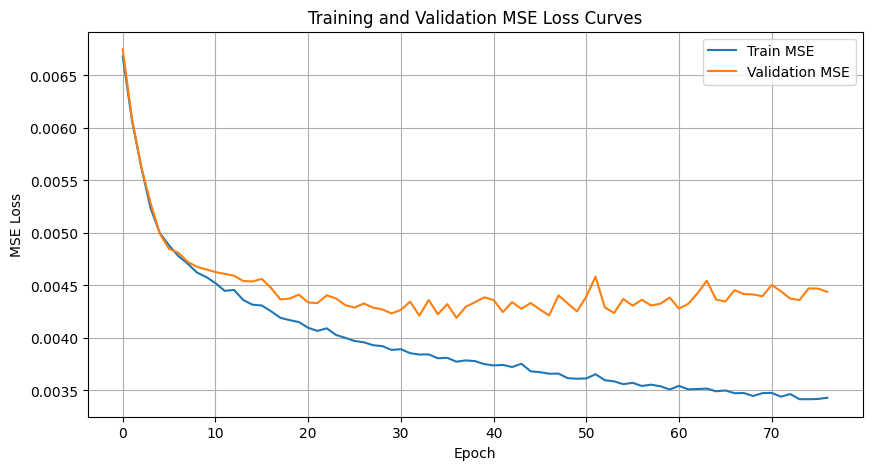

,model,type,train-mse,val-mse,test-mse,train-mre,val-mre,test-mre
0,(mSHRED): TR+cnn,(T.0): always-available stations only,0.004128,0.004438,0.006931,0.127817,0.135475,0.164078
1,(mSHRED): LSTM+cnn,(S.0): always-available stations only,0.004119,0.004407,0.007174,0.127691,0.134495,0.165759
2,(mSHRED): TR+cnn,(T.1.A): median imputation for missing sensors,0.003774,0.004191,0.006484,0.123139,0.131816,0.159573


In [20]:
# mSHRED TRAINING
model_args = dict(
    # Encoder
    encoder="transformer", encoder_depth=ENCODER_DEPTH, input_size=nn_input_shape, n_heads=N_HEADS,
    dim_feedforward=DIM_FEEDFORWARD, hidden_size=HIDDEN_SIZE, input_length=LAGS, double_channels=False,
    # Decoder
    decoder=DECODER, decoder_hidden_sizes=DECODER_HIDDEN_SIZES, output_size=nn_output_shape, dropout=DROPOUT,
)
mshred = mSHRED(args=model_args).to(device)

# Use cosine annealing LR schedule
train_errors, valid_errors = fit(
    mshred, train_dataset, val_dataset,
    optimizer=OPTIMIZER, lr=LEARNING_RATE, num_epochs=NUM_EPOCHS, patience=PATIENCE, verbose=VERBOSE_TRAIN,
    lr_scheduler=LR_SCHEDULER, scheduler_step_size=SCHEDULER_STEP_SIZE,
)

# PLOT TRAINING CURVES
plot_training_curves(train_errors, valid_errors)

# EVALUATION
test_error = evaluate_model(
    evaluate, mshred, train_dataset, val_dataset, test_dataset,
    model=f"(mSHRED): TR+{DECODER}", type="(T.1.A): median imputation for missing sensors"
 )

ERRORS.append(test_error)
dataframe_errors = pd.DataFrame(ERRORS)
display(dataframe_errors)
dataframe_errors.to_csv("dataframe_errors.csv", index=False)

Saved plot: /home/matteo/Documents/Masked-SHRED/Notebooks/HYDRO/outputs/shred_(T.1.A)_median_imputation.png


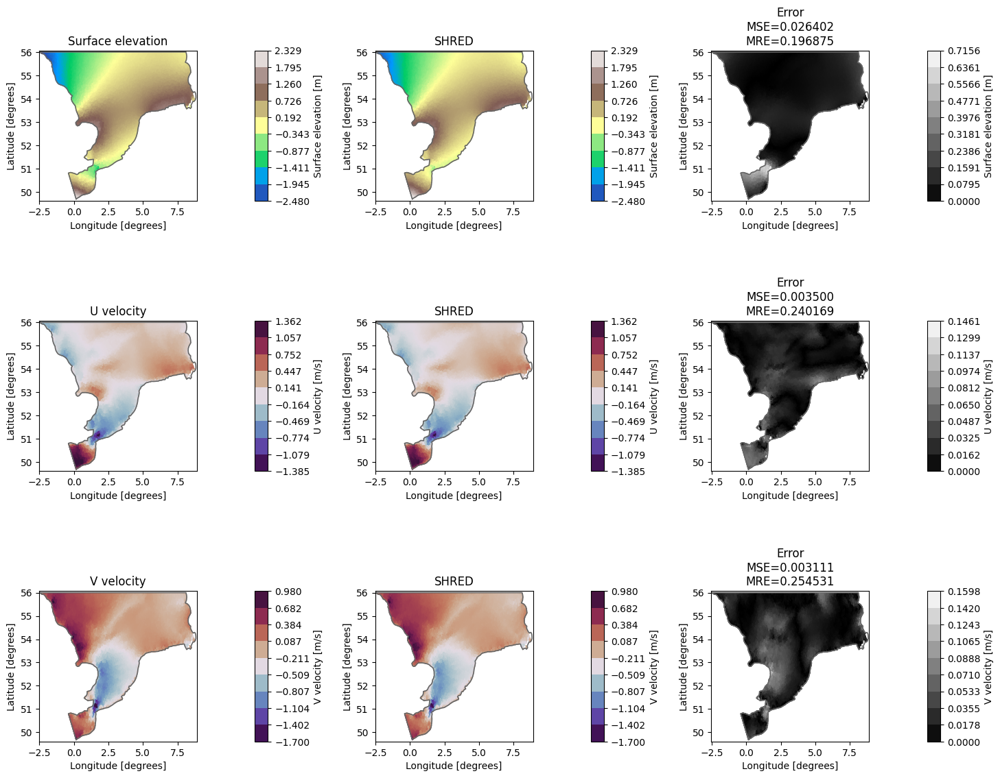

In [21]:
# mSHRED RECONSTRUCTION
engine = SHREDEngine(manager, mshred)
test_reconstruction = engine.sensor_to_reconstruction_dataset(test_dataset)
ds_r = align_ds(manager.test_indices, ds, permuted_indices, lenmonths, geom)
ds_shred, ds_error = plot_shred_reconstruction(test_reconstruction, ds_r, geom, title_suffix="(T.1.A)_median_imputation")

del engine, test_reconstruction, ds_shred, ds_error, mshred, manager, train_dataset, val_dataset, test_dataset, model_args, train_errors, valid_errors, test_error, nn_input_shape, nn_output_shape

## (T.1.B): Mean imputer

In [22]:
# Data manager
manager = ROMDataManager(lags=LAGS, train_size=TRAIN_SIZE, val_size=VAL_SIZE, test_size=TEST_SIZE)
# add data to manager
manager.add_data(H, id="Surface elevation", compress=COMPRESS_H, measurements=measurements, imputer="mean")
manager.add_data(U, id="U velocity", compress=COMPRESS_U)
manager.add_data(V, id="V velocity", compress=COMPRESS_V)
# prepare datasets
train_dataset, val_dataset, test_dataset = manager.prepare(verbose=True)

# network input and output shapes
nn_input_shape = train_dataset[0][0].shape[1]
nn_output_shape = train_dataset[0][1].shape[0]
print("\nInput shape for the model:", nn_input_shape)
print("Output shape for the model:", nn_output_shape)

Nuber of nan values in measurements after imputation: 0
Residual energy of Surface elevation after keeping 12 modes: 0.1755 %
Residual energy of U velocity after keeping 40 modes: 0.1998 %
Residual energy of V velocity after keeping 68 modes: 0.1933 %

Datasets: ['Surface elevation', 'U velocity', 'V velocity']

Number of nan values in sensor measurements after masking: 0

Data shapes after preparation:
Train:	 torch.Size([27360, 48, 4]) -> torch.Size([27360, 120])
Val:	 torch.Size([2880, 48, 4]) -> torch.Size([2880, 120])
Test:	 torch.Size([4320, 48, 4]) -> torch.Size([4320, 120])

Input shape for the model: 4
Output shape for the model: 120


Starting training...


Training:  36%|███▌      | 71/200 [06:31<11:51,  5.51s/it, Train Loss=0.00353, Val Loss=0.00461, Patience=39, Best Val Loss=0.00429, LR=7.13e-04]

Early stopping at epoch 72
Training completed with best validation loss: 0.0043


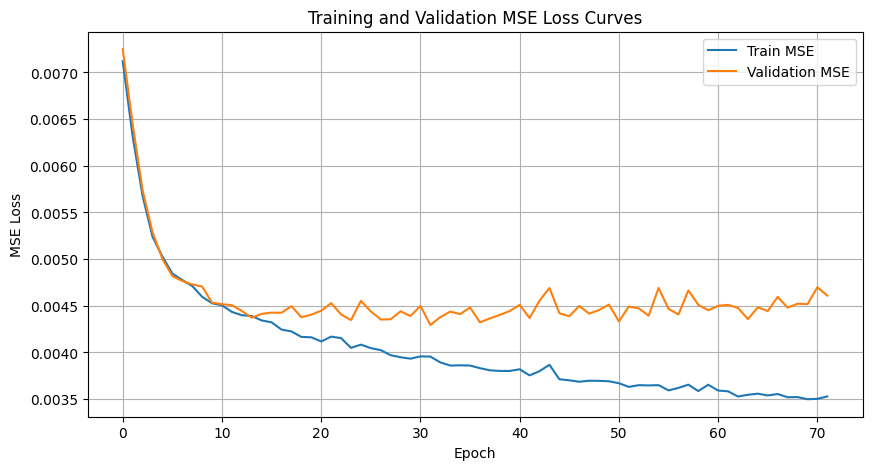

,model,type,train-mse,val-mse,test-mse,train-mre,val-mre,test-mre
0,(mSHRED): TR+cnn,(T.0): always-available stations only,0.004128,0.004438,0.006931,0.127817,0.135475,0.164078
1,(mSHRED): LSTM+cnn,(S.0): always-available stations only,0.004119,0.004407,0.007174,0.127691,0.134495,0.165759
2,(mSHRED): TR+cnn,(T.1.A): median imputation for missing sensors,0.003774,0.004191,0.006484,0.123139,0.131816,0.159573
3,(mSHRED): TR+cnn,(T.1.B): mean imputation for missing sensors,0.003955,0.004294,0.006661,0.126321,0.133619,0.161729


In [23]:
# mSHRED TRAINING
model_args = dict(
    # Encoder
    encoder="transformer", encoder_depth=ENCODER_DEPTH, input_size=nn_input_shape, n_heads=N_HEADS,
    dim_feedforward=DIM_FEEDFORWARD, hidden_size=HIDDEN_SIZE, input_length=LAGS, double_channels=False,
    # Decoder
    decoder=DECODER, decoder_hidden_sizes=DECODER_HIDDEN_SIZES, output_size=nn_output_shape, dropout=DROPOUT,
)
mshred = mSHRED(args=model_args).to(device)

# Use cosine annealing LR schedule
train_errors, valid_errors = fit(
    mshred, train_dataset, val_dataset,
    optimizer=OPTIMIZER, lr=LEARNING_RATE, num_epochs=NUM_EPOCHS, patience=PATIENCE, verbose=VERBOSE_TRAIN,
    lr_scheduler=LR_SCHEDULER, scheduler_step_size=SCHEDULER_STEP_SIZE,
)

# PLOT TRAINING CURVES
plot_training_curves(train_errors, valid_errors)

# EVALUATION
test_error = evaluate_model(
    evaluate, mshred, train_dataset, val_dataset, test_dataset,
    model=f"(mSHRED): TR+{DECODER}", type="(T.1.B): mean imputation for missing sensors"
 )

ERRORS.append(test_error)
dataframe_errors = pd.DataFrame(ERRORS)
display(dataframe_errors)
dataframe_errors.to_csv("dataframe_errors.csv", index=False)

Saved plot: /home/matteo/Documents/Masked-SHRED/Notebooks/HYDRO/outputs/shred_(T.1.B)_mean_imputation.png


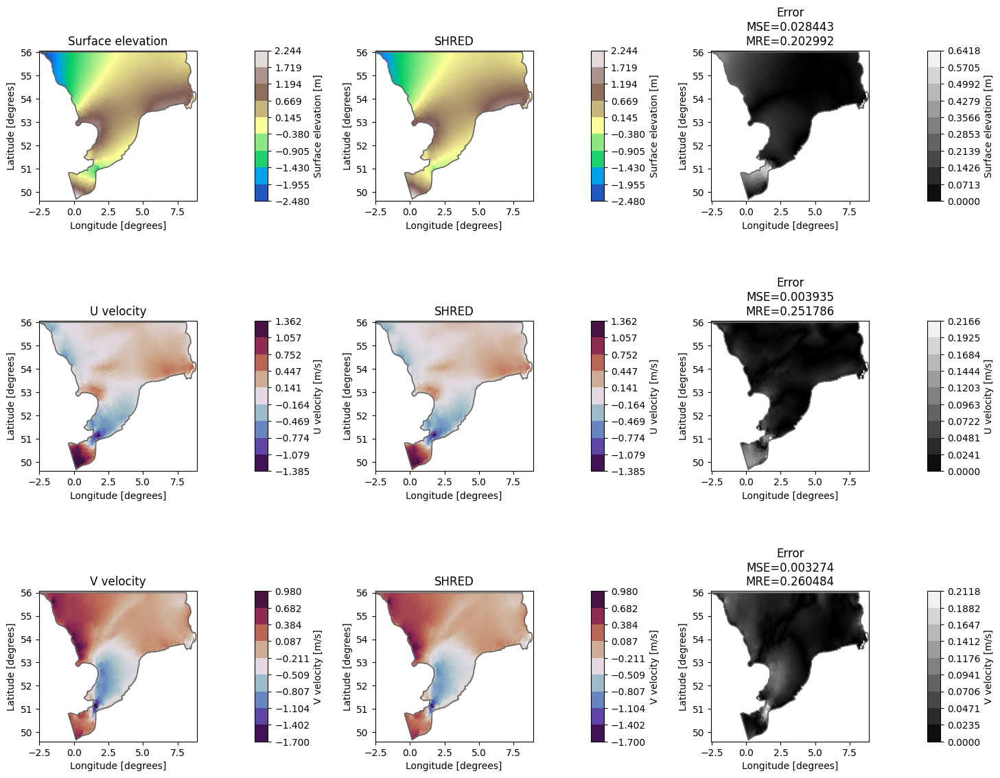

In [24]:
# mSHRED RECONSTRUCTION
engine = SHREDEngine(manager, mshred)
test_reconstruction = engine.sensor_to_reconstruction_dataset(test_dataset)
ds_r = align_ds(manager.test_indices, ds, permuted_indices, lenmonths, geom)
ds_shred, ds_error = plot_shred_reconstruction(test_reconstruction, ds_r, geom, title_suffix="(T.1.B)_mean_imputation")

del engine, test_reconstruction, ds_shred, ds_error, mshred, manager, train_dataset, val_dataset, test_dataset, model_args, train_errors, valid_errors, test_error, nn_input_shape, nn_output_shape

## (T.1.C): Last value imputer

In [25]:
# Data manager
manager = ROMDataManager(lags=LAGS, train_size=TRAIN_SIZE, val_size=VAL_SIZE, test_size=TEST_SIZE)
# add data to manager
manager.add_data(H, id="Surface elevation", compress=COMPRESS_H, measurements=measurements, imputer="last_value")
manager.add_data(U, id="U velocity", compress=COMPRESS_U)
manager.add_data(V, id="V velocity", compress=COMPRESS_V)
# prepare datasets
train_dataset, val_dataset, test_dataset = manager.prepare(verbose=True)

# network input and output shapes
nn_input_shape = train_dataset[0][0].shape[1]
nn_output_shape = train_dataset[0][1].shape[0]
print("\nInput shape for the model:", nn_input_shape)
print("Output shape for the model:", nn_output_shape)

Nuber of nan values in measurements after imputation: 0
Residual energy of Surface elevation after keeping 12 modes: 0.1755 %
Residual energy of U velocity after keeping 40 modes: 0.1998 %
Residual energy of V velocity after keeping 68 modes: 0.1933 %

Datasets: ['Surface elevation', 'U velocity', 'V velocity']

Number of nan values in sensor measurements after masking: 0

Data shapes after preparation:
Train:	 torch.Size([27360, 48, 4]) -> torch.Size([27360, 120])
Val:	 torch.Size([2880, 48, 4]) -> torch.Size([2880, 120])
Test:	 torch.Size([4320, 48, 4]) -> torch.Size([4320, 120])

Input shape for the model: 4
Output shape for the model: 120


Starting training...


Training:  34%|███▍      | 68/200 [06:16<12:10,  5.53s/it, Train Loss=0.00350, Val Loss=0.00458, Patience=39, Best Val Loss=0.00422, LR=7.34e-04]

Early stopping at epoch 69
Training completed with best validation loss: 0.0042


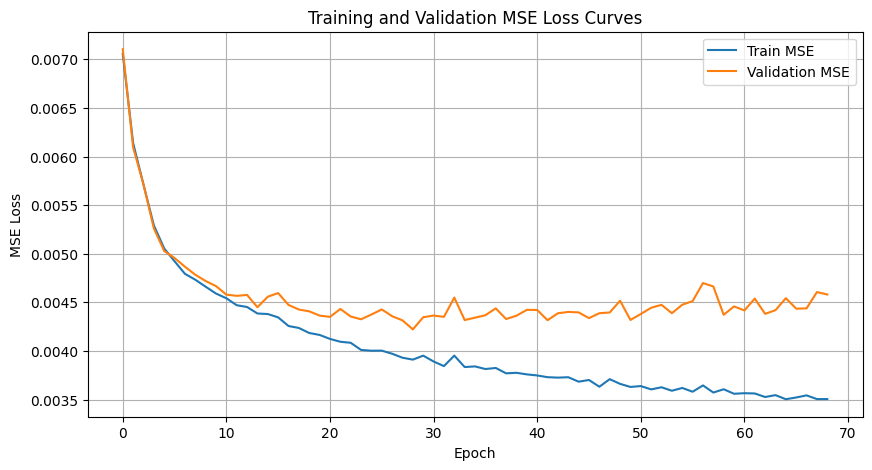

,model,type,train-mse,val-mse,test-mse,train-mre,val-mre,test-mre
0,(mSHRED): TR+cnn,(T.0): always-available stations only,0.004128,0.004438,0.006931,0.127817,0.135475,0.164078
1,(mSHRED): LSTM+cnn,(S.0): always-available stations only,0.004119,0.004407,0.007174,0.127691,0.134495,0.165759
2,(mSHRED): TR+cnn,(T.1.A): median imputation for missing sensors,0.003774,0.004191,0.006484,0.123139,0.131816,0.159573
3,(mSHRED): TR+cnn,(T.1.B): mean imputation for missing sensors,0.003955,0.004294,0.006661,0.126321,0.133619,0.161729
4,(mSHRED): TR+cnn,(T.1.C): last-value imputation for missing sen...,0.003910,0.004221,0.006563,0.125312,0.132687,0.160349


In [26]:
# mSHRED TRAINING
model_args = dict(
    # Encoder
    encoder="transformer", encoder_depth=ENCODER_DEPTH, input_size=nn_input_shape, n_heads=N_HEADS,
    dim_feedforward=DIM_FEEDFORWARD, hidden_size=HIDDEN_SIZE, input_length=LAGS, double_channels=False,
    # Decoder
    decoder=DECODER, decoder_hidden_sizes=DECODER_HIDDEN_SIZES, output_size=nn_output_shape, dropout=DROPOUT,
)
mshred = mSHRED(args=model_args).to(device)

# Use cosine annealing LR schedule
train_errors, valid_errors = fit(
    mshred, train_dataset, val_dataset,
    optimizer=OPTIMIZER, lr=LEARNING_RATE, num_epochs=NUM_EPOCHS, patience=PATIENCE, verbose=VERBOSE_TRAIN,
    lr_scheduler=LR_SCHEDULER, scheduler_step_size=SCHEDULER_STEP_SIZE,
)

# PLOT TRAINING CURVES
plot_training_curves(train_errors, valid_errors)

# EVALUATION
test_error = evaluate_model(
    evaluate, mshred, train_dataset, val_dataset, test_dataset,
    model=f"(mSHRED): TR+{DECODER}", type="(T.1.C): last-value imputation for missing sensors"
 )

ERRORS.append(test_error)
dataframe_errors = pd.DataFrame(ERRORS)
display(dataframe_errors)
dataframe_errors.to_csv("dataframe_errors.csv", index=False)

Saved plot: /home/matteo/Documents/Masked-SHRED/Notebooks/HYDRO/outputs/shred_(T.1.C)_last_value_imputation.png


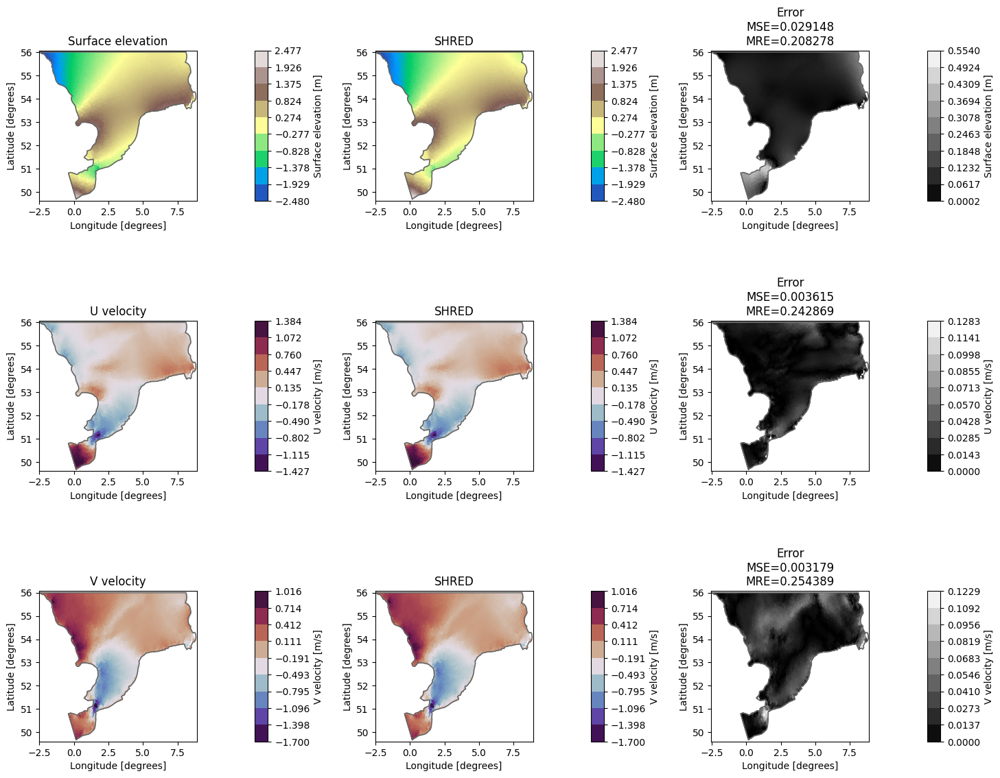

In [27]:
# mSHRED RECONSTRUCTION
engine = SHREDEngine(manager, mshred)
test_reconstruction = engine.sensor_to_reconstruction_dataset(test_dataset)
ds_r = align_ds(manager.test_indices, ds, permuted_indices, lenmonths, geom)
ds_shred, ds_error = plot_shred_reconstruction(test_reconstruction, ds_r, geom, title_suffix="(T.1.C)_last_value_imputation")

del engine, test_reconstruction, ds_shred, ds_error, mshred, manager, train_dataset, val_dataset, test_dataset, model_args, train_errors, valid_errors, test_error, nn_input_shape, nn_output_shape

## (T.2.A) GRUD

In [28]:
# Data manager
manager = ROMDataManager(lags=LAGS, train_size=TRAIN_SIZE, val_size=VAL_SIZE, test_size=TEST_SIZE)
# add data to manager
manager.add_data(H, id="Surface elevation", compress=COMPRESS_H, measurements=measurements)
manager.add_data(U, id="U velocity", compress=COMPRESS_U)
manager.add_data(V, id="V velocity", compress=COMPRESS_V)
# prepare datasets
train_dataset, val_dataset, test_dataset, X_mean = manager.prepare(verbose=True, masking_type="grud")

# network input and output shapes
nn_input_shape = train_dataset[0][0].shape[-1]
nn_output_shape = train_dataset[0][1].shape[0]
print("\nInput shape for the model:", nn_input_shape)
print("Output shape for the model:", nn_output_shape)

Nuber of nan values in measurements after imputation: 26393
Residual energy of Surface elevation after keeping 12 modes: 0.1755 %
Residual energy of U velocity after keeping 40 modes: 0.1998 %
Residual energy of V velocity after keeping 68 modes: 0.1932 %

Datasets: ['Surface elevation', 'U velocity', 'V velocity']

Number of nan values in sensor measurements after masking: 0

Data shapes after preparation:
Train:	 torch.Size([27360, 4, 48, 4]) -> torch.Size([27360, 120])
Val:	 torch.Size([2880, 4, 48, 4]) -> torch.Size([2880, 120])
Test:	 torch.Size([4320, 4, 48, 4]) -> torch.Size([4320, 120])

Input shape for the model: 4
Output shape for the model: 120


Starting training...


Training:  48%|████▊     | 95/200 [19:31<21:34, 12.33s/it, Train Loss=0.00367, Val Loss=0.00468, Patience=39, Best Val Loss=0.00458, LR=5.31e-04]

Early stopping at epoch 96
Training completed with best validation loss: 0.0046


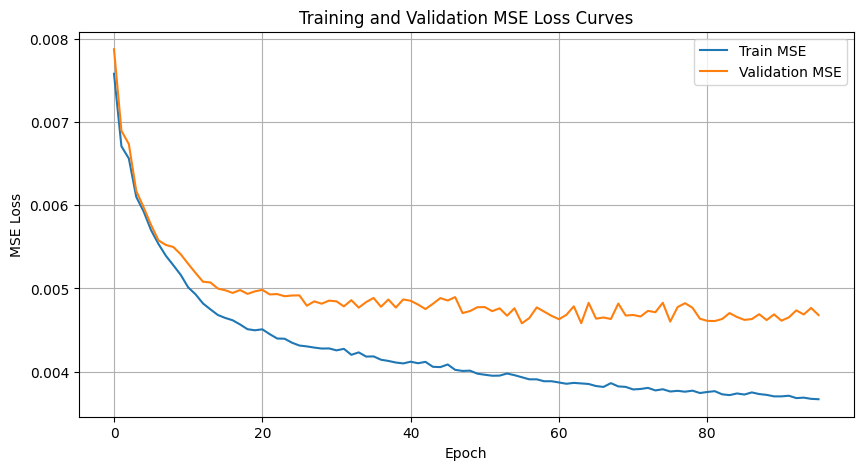

,model,type,train-mse,val-mse,test-mse,train-mre,val-mre,test-mre
0,(mSHRED): TR+cnn,(T.0): always-available stations only,0.004128,0.004438,0.006931,0.127817,0.135475,0.164078
1,(mSHRED): LSTM+cnn,(S.0): always-available stations only,0.004119,0.004407,0.007174,0.127691,0.134495,0.165759
2,(mSHRED): TR+cnn,(T.1.A): median imputation for missing sensors,0.003774,0.004191,0.006484,0.123139,0.131816,0.159573
3,(mSHRED): TR+cnn,(T.1.B): mean imputation for missing sensors,0.003955,0.004294,0.006661,0.126321,0.133619,0.161729
4,(mSHRED): TR+cnn,(T.1.C): last-value imputation for missing sen...,0.003910,0.004221,0.006563,0.125312,0.132687,0.160349
5,(mSHRED): GRUD+cnn,(T.2.A): GRUD,0.003932,0.004580,0.006809,0.126058,0.138078,0.163755


In [29]:
# GRUD TRAINING
model_args = dict(
    # Encoder
    encoder="grud", input_size=nn_input_shape, hidden_size=HIDDEN_SIZE, X_mean=X_mean,
    # Decoder
    decoder=DECODER, decoder_hidden_sizes=DECODER_HIDDEN_SIZES, output_size=nn_output_shape, dropout=DROPOUT,
)
mshred = mSHRED(args=model_args).to(device)

# Use cosine annealing LR schedule
train_errors, valid_errors = fit(
    mshred, train_dataset, val_dataset,
    optimizer=OPTIMIZER, lr=LEARNING_RATE, num_epochs=NUM_EPOCHS, patience=PATIENCE, verbose=VERBOSE_TRAIN,
    lr_scheduler=LR_SCHEDULER, scheduler_step_size=SCHEDULER_STEP_SIZE,
)

# PLOT TRAINING CURVES
plot_training_curves(train_errors, valid_errors)

# EVALUATION
test_error = evaluate_model(
    evaluate, mshred, train_dataset, val_dataset, test_dataset,
    model=f"(mSHRED): GRUD+{DECODER}", type="(T.2.A): GRUD"
 )

ERRORS.append(test_error)
dataframe_errors = pd.DataFrame(ERRORS)
display(dataframe_errors)
dataframe_errors.to_csv("dataframe_errors.csv", index=False)

Saved plot: /home/matteo/Documents/Masked-SHRED/Notebooks/HYDRO/outputs/shred_(T.2.A)_GRUD.png


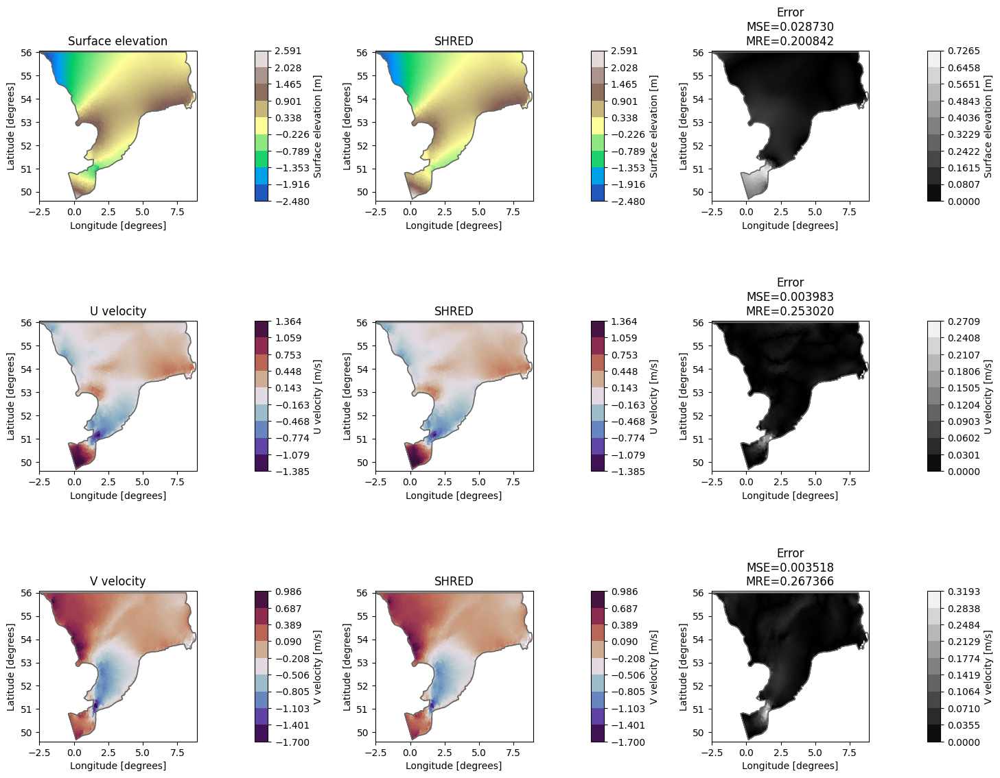

In [30]:
# mSHRED RECONSTRUCTION
engine = SHREDEngine(manager, mshred)
test_reconstruction = engine.sensor_to_reconstruction_dataset(test_dataset)
ds_r = align_ds(manager.test_indices, ds, permuted_indices, lenmonths, geom)
ds_grud, ds_error_grud = plot_shred_reconstruction(test_reconstruction, ds_r, geom, title_suffix="(T.2.A)_GRUD")

del engine, test_reconstruction, ds_grud, ds_error_grud, mshred, model_args, train_errors, valid_errors, test_error

## (T.2.B): Attn-GRUD

Starting training...


Training:  54%|█████▎    | 107/200 [38:03<33:04, 21.34s/it, Train Loss=0.00374, Val Loss=0.00473, Patience=39, Best Val Loss=0.00460, LR=4.37e-04] 

Early stopping at epoch 108
Training completed with best validation loss: 0.0046


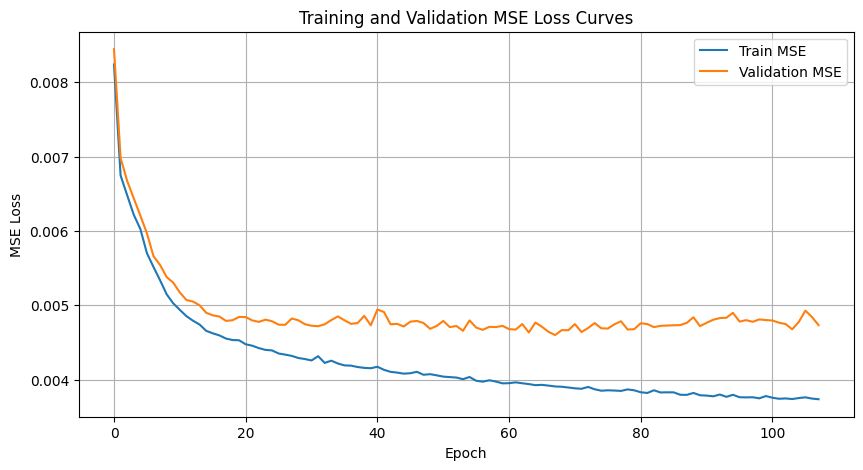

,model,type,train-mse,val-mse,test-mse,train-mre,val-mre,test-mre
0,(mSHRED): TR+cnn,(T.0): always-available stations only,0.004128,0.004438,0.006931,0.127817,0.135475,0.164078
1,(mSHRED): LSTM+cnn,(S.0): always-available stations only,0.004119,0.004407,0.007174,0.127691,0.134495,0.165759
2,(mSHRED): TR+cnn,(T.1.A): median imputation for missing sensors,0.003774,0.004191,0.006484,0.123139,0.131816,0.159573
3,(mSHRED): TR+cnn,(T.1.B): mean imputation for missing sensors,0.003955,0.004294,0.006661,0.126321,0.133619,0.161729
4,(mSHRED): TR+cnn,(T.1.C): last-value imputation for missing sen...,0.003910,0.004221,0.006563,0.125312,0.132687,0.160349
5,(mSHRED): GRUD+cnn,(T.2.A): GRUD,0.003932,0.004580,0.006809,0.126058,0.138078,0.163755
6,(mSHRED): Attn-GRUD+cnn,(T.2.B): Attn-GRUD,0.003910,0.004601,0.006780,0.125298,0.137999,0.163068


In [31]:
# Attn-GRUD TRAINING
model_args = dict(
    # Encoder
    encoder="att_grud", input_size=nn_input_shape, hidden_size=HIDDEN_SIZE, X_mean=X_mean,
    # Decoder
    decoder=DECODER, decoder_hidden_sizes=DECODER_HIDDEN_SIZES, output_size=nn_output_shape, dropout=DROPOUT,
)
mshred = mSHRED(args=model_args).to(device)

# Use cosine annealing LR schedule
train_errors, valid_errors = fit(
    mshred, train_dataset, val_dataset,
    optimizer=OPTIMIZER, lr=LEARNING_RATE, num_epochs=NUM_EPOCHS, patience=PATIENCE, verbose=VERBOSE_TRAIN,
    lr_scheduler=LR_SCHEDULER, scheduler_step_size=SCHEDULER_STEP_SIZE,
)

# PLOT TRAINING CURVES
plot_training_curves(train_errors, valid_errors)

# EVALUATION
test_error = evaluate_model(
    evaluate, mshred, train_dataset, val_dataset, test_dataset,
    model=f"(mSHRED): Attn-GRUD+{DECODER}", type="(T.2.B): Attn-GRUD"
 )

ERRORS.append(test_error)
dataframe_errors = pd.DataFrame(ERRORS)
display(dataframe_errors)
dataframe_errors.to_csv("dataframe_errors.csv", index=False)

Saved plot: /home/matteo/Documents/Masked-SHRED/Notebooks/HYDRO/outputs/shred_(T.2.B)_Attn-GRUD.png


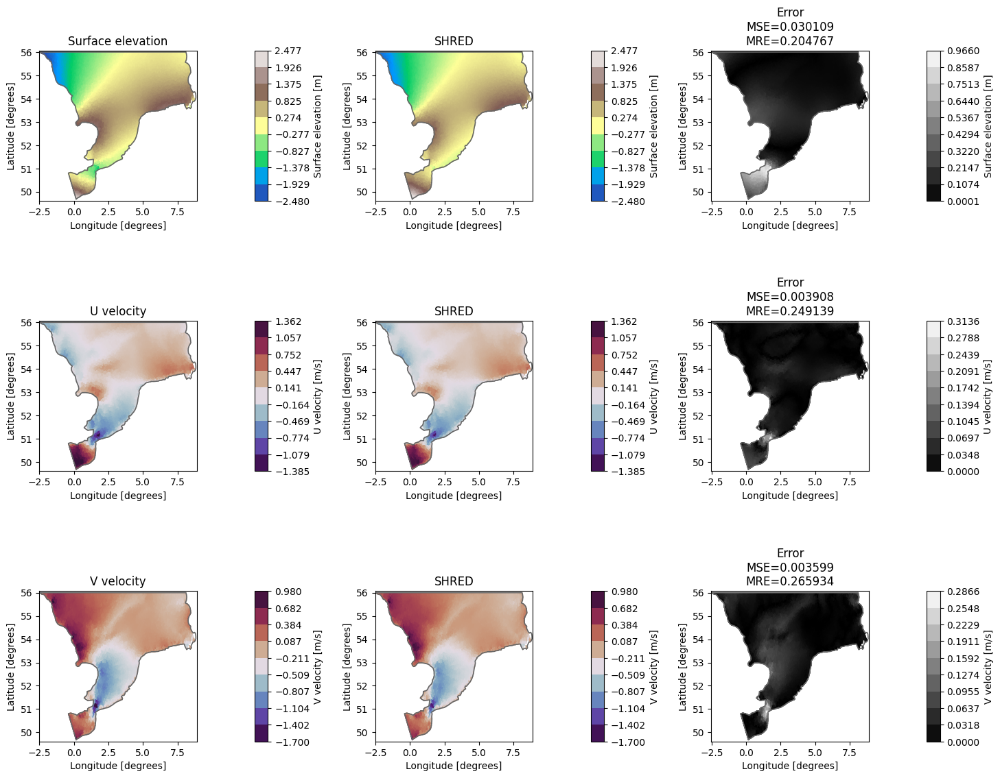

In [32]:
# mSHRED RECONSTRUCTION
engine = SHREDEngine(manager, mshred)
test_reconstruction = engine.sensor_to_reconstruction_dataset(test_dataset)
ds_r = align_ds(manager.test_indices, ds, permuted_indices, lenmonths, geom)
ds_grud, ds_error_grud = plot_shred_reconstruction(test_reconstruction, ds_r, geom, title_suffix="(T.2.B)_Attn-GRUD")

del engine, test_reconstruction, ds_grud, ds_error_grud, mshred, manager, train_dataset, val_dataset, test_dataset, model_args, train_errors, valid_errors, test_error, nn_input_shape, nn_output_shape, X_mean

## (T.3.A): Masking

In [33]:
# Data manager
manager = ROMDataManager(lags=LAGS, train_size=TRAIN_SIZE, val_size=VAL_SIZE, test_size=TEST_SIZE)
# add data to manager
manager.add_data(H, id="Surface elevation", compress=COMPRESS_H, measurements=measurements)
manager.add_data(U, id="U velocity", compress=COMPRESS_U)
manager.add_data(V, id="V velocity", compress=COMPRESS_V)
# prepare datasets
train_dataset, val_dataset, test_dataset = manager.prepare(verbose=True, masking_type=MASKING_TYPE)

# network input and output shapes
nn_input_shape = train_dataset.X.shape[-1]
nn_output_shape = train_dataset.Y.shape[-1]
print("\nInput shape for the model:", nn_input_shape)
print("Output shape for the model:", nn_output_shape)

Nuber of nan values in measurements after imputation: 26393
Residual energy of Surface elevation after keeping 12 modes: 0.1755 %
Residual energy of U velocity after keeping 40 modes: 0.1998 %
Residual energy of V velocity after keeping 68 modes: 0.1932 %

Datasets: ['Surface elevation', 'U velocity', 'V velocity']

Number of nan values in sensor measurements after masking: 26393

Data shapes after preparation:
Train:	 torch.Size([27360, 48, 4]) -> torch.Size([27360, 120])
Val:	 torch.Size([2880, 48, 4]) -> torch.Size([2880, 120])
Test:	 torch.Size([4320, 48, 4]) -> torch.Size([4320, 120])

Input shape for the model: 4
Output shape for the model: 120


Starting training...


Training:  31%|███       | 62/200 [04:53<10:52,  4.73s/it, Train Loss=0.00348, Val Loss=0.00458, Patience=39, Best Val Loss=0.00432, LR=7.75e-04]

Early stopping at epoch 63
Training completed with best validation loss: 0.0043


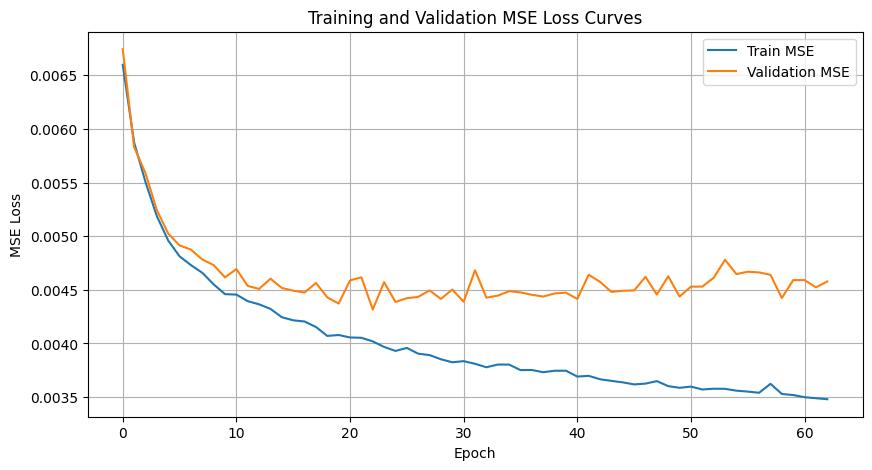

,model,type,train-mse,val-mse,test-mse,train-mre,val-mre,test-mre
0,(mSHRED): TR+cnn,(T.0): always-available stations only,0.004128,0.004438,0.006931,0.127817,0.135475,0.164078
1,(mSHRED): LSTM+cnn,(S.0): always-available stations only,0.004119,0.004407,0.007174,0.127691,0.134495,0.165759
2,(mSHRED): TR+cnn,(T.1.A): median imputation for missing sensors,0.003774,0.004191,0.006484,0.123139,0.131816,0.159573
3,(mSHRED): TR+cnn,(T.1.B): mean imputation for missing sensors,0.003955,0.004294,0.006661,0.126321,0.133619,0.161729
4,(mSHRED): TR+cnn,(T.1.C): last-value imputation for missing sen...,0.003910,0.004221,0.006563,0.125312,0.132687,0.160349
5,(mSHRED): GRUD+cnn,(T.2.A): GRUD,0.003932,0.004580,0.006809,0.126058,0.138078,0.163755
6,(mSHRED): Attn-GRUD+cnn,(T.2.B): Attn-GRUD,0.003910,0.004601,0.006780,0.125298,0.137999,0.163068
7,(mSHRED): TR+cnn,(T.3.A): masking,0.004019,0.004317,0.006623,0.127119,0.134015,0.161857


In [34]:
# mSHRED TRAINING
model_args = dict(
    # Encoder
    encoder="transformer", encoder_depth=ENCODER_DEPTH, input_size=nn_input_shape, n_heads=N_HEADS,
    dim_feedforward=DIM_FEEDFORWARD, hidden_size=HIDDEN_SIZE, input_length=LAGS, double_channels=False,
    # Decoder
    decoder=DECODER, decoder_hidden_sizes=DECODER_HIDDEN_SIZES, output_size=nn_output_shape, dropout=DROPOUT, 
)
mshred = mSHRED(args=model_args).to(device)

# Use cosine annealing LR schedule
train_errors, valid_errors = fit(
    mshred, train_dataset, val_dataset,
    optimizer=OPTIMIZER, lr=LEARNING_RATE, num_epochs=NUM_EPOCHS, patience=PATIENCE, verbose=VERBOSE_TRAIN,
    lr_scheduler=LR_SCHEDULER, scheduler_step_size=SCHEDULER_STEP_SIZE,
    masking_type=MASKING_TYPE,
)

# PLOT TRAINING CURVES
plot_training_curves(train_errors, valid_errors)

# EVALUATION
test_error = evaluate_model(
    evaluate, mshred, train_dataset, val_dataset, test_dataset,
    model=f"(mSHRED): TR+{DECODER}", type="(T.3.A): masking", masking_type=MASKING_TYPE
)

# Save errors to dataframe
ERRORS.append(test_error)
dataframe_errors = pd.DataFrame(ERRORS)
display(dataframe_errors)
dataframe_errors.to_csv("dataframe_errors.csv", index=False)

Saved plot: /home/matteo/Documents/Masked-SHRED/Notebooks/HYDRO/outputs/shred_(T.3.A)_masking.png


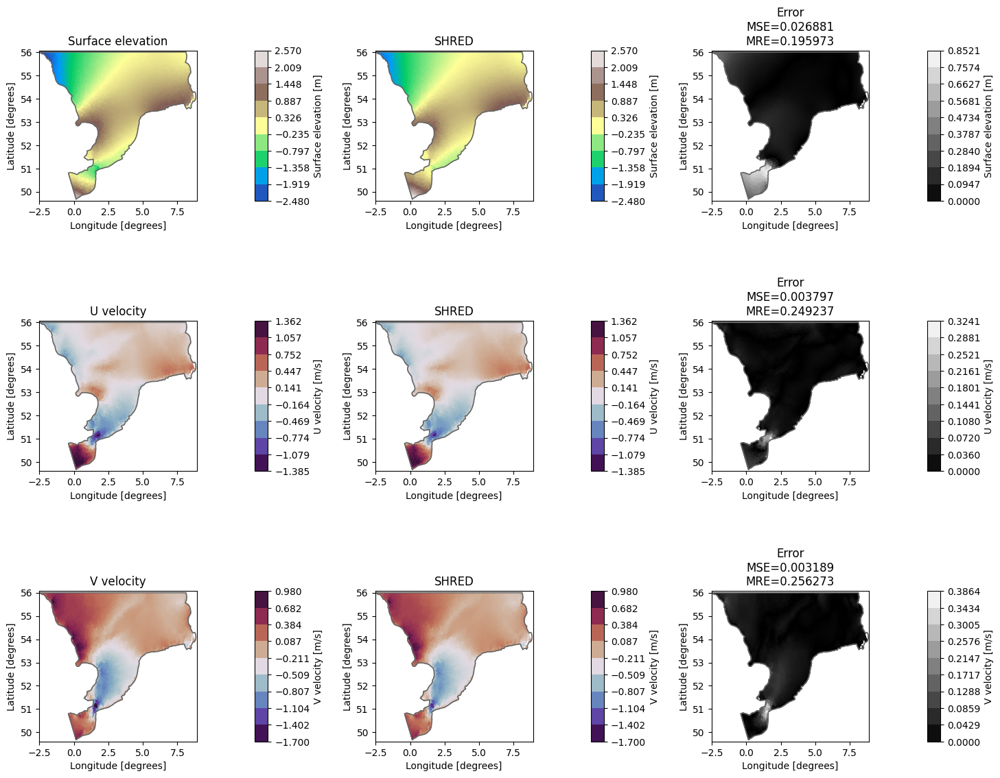

In [35]:
# mSHRED RECONSTRUCTION
engine = SHREDEngine(manager, mshred)
test_reconstruction = engine.sensor_to_reconstruction_dataset(test_dataset)
ds_r = align_ds(manager.test_indices, ds, permuted_indices, lenmonths, geom)
ds_shred, ds_error = plot_shred_reconstruction(test_reconstruction, ds_r, geom, title_suffix="(T.3.A)_masking")

del engine, test_reconstruction, ds_shred, ds_error, mshred, model_args, train_errors, valid_errors, test_error

## (T.3.B): Masking x2 channels

Starting training...


Training:  30%|███       | 61/200 [04:37<10:32,  4.55s/it, Train Loss=0.00352, Val Loss=0.00458, Patience=39, Best Val Loss=0.00439, LR=7.81e-04]

Early stopping at epoch 62
Training completed with best validation loss: 0.0044


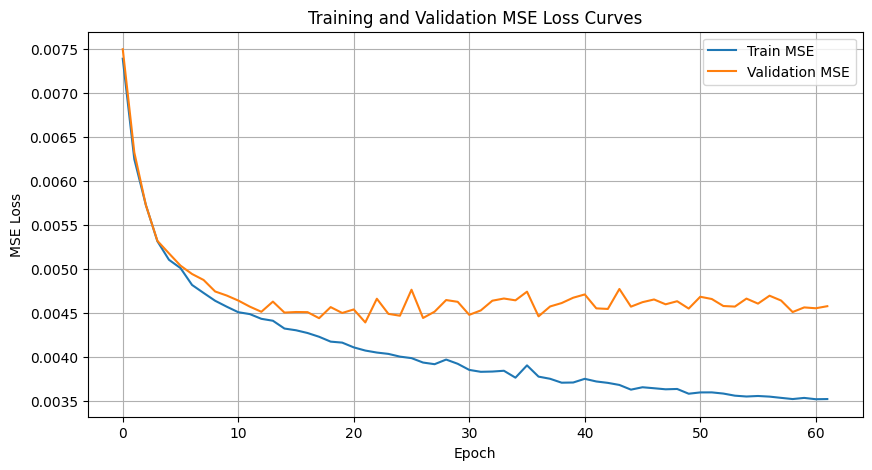

,model,type,train-mse,val-mse,test-mse,train-mre,val-mre,test-mre
0,(mSHRED): TR+cnn,(T.0): always-available stations only,0.004128,0.004438,0.006931,0.127817,0.135475,0.164078
1,(mSHRED): LSTM+cnn,(S.0): always-available stations only,0.004119,0.004407,0.007174,0.127691,0.134495,0.165759
2,(mSHRED): TR+cnn,(T.1.A): median imputation for missing sensors,0.003774,0.004191,0.006484,0.123139,0.131816,0.159573
3,(mSHRED): TR+cnn,(T.1.B): mean imputation for missing sensors,0.003955,0.004294,0.006661,0.126321,0.133619,0.161729
4,(mSHRED): TR+cnn,(T.1.C): last-value imputation for missing sen...,0.003910,0.004221,0.006563,0.125312,0.132687,0.160349
5,(mSHRED): GRUD+cnn,(T.2.A): GRUD,0.003932,0.004580,0.006809,0.126058,0.138078,0.163755
6,(mSHRED): Attn-GRUD+cnn,(T.2.B): Attn-GRUD,0.003910,0.004601,0.006780,0.125298,0.137999,0.163068
7,(mSHRED): TR+cnn,(T.3.A): masking,0.004019,0.004317,0.006623,0.127119,0.134015,0.161857
8,(mSHRED): TR+cnn,(T.3.B): masking x2 channels,0.004072,0.004391,0.006717,0.127659,0.136133,0.163249


In [36]:
# mSHRED TRAINING
model_args = dict(
    # Encoder
    encoder="transformer", encoder_depth=ENCODER_DEPTH, input_size=nn_input_shape, n_heads=N_HEADS,
    dim_feedforward=DIM_FEEDFORWARD, hidden_size=HIDDEN_SIZE, input_length=LAGS, double_channels=True,
    # Decoder
    decoder=DECODER, decoder_hidden_sizes=DECODER_HIDDEN_SIZES, output_size=nn_output_shape, dropout=DROPOUT, 
 )
mshred = mSHRED(args=model_args).to(device)

# Use cosine annealing LR schedule
train_errors, valid_errors = fit(
    mshred, train_dataset, val_dataset,
    optimizer=OPTIMIZER, lr=LEARNING_RATE, num_epochs=NUM_EPOCHS, patience=PATIENCE, verbose=VERBOSE_TRAIN,
    lr_scheduler=LR_SCHEDULER, scheduler_step_size=SCHEDULER_STEP_SIZE,
    masking_type=MASKING_TYPE,
 )

# PLOT TRAINING CURVES
plot_training_curves(train_errors, valid_errors)

# EVALUATION
test_error = evaluate_model(
    evaluate, mshred, train_dataset, val_dataset, test_dataset,
    model=f"(mSHRED): TR+{DECODER}", type="(T.3.B): masking x2 channels", masking_type=MASKING_TYPE
 )

# Save errors to dataframe
ERRORS.append(test_error)
dataframe_errors = pd.DataFrame(ERRORS)
display(dataframe_errors)
dataframe_errors.to_csv("dataframe_errors.csv", index=False)

Saved plot: /home/matteo/Documents/Masked-SHRED/Notebooks/HYDRO/outputs/shred_(T.3.B)_masking_x2_channels.png


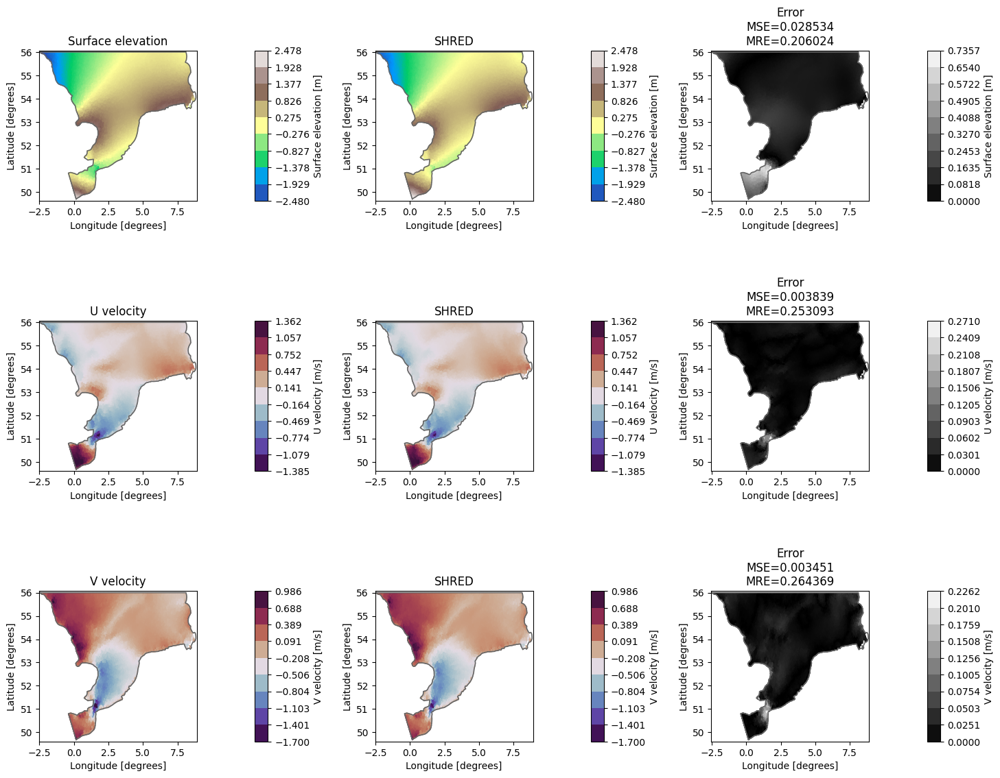

In [37]:
# mSHRED RECONSTRUCTION
engine = SHREDEngine(manager, mshred)
test_reconstruction = engine.sensor_to_reconstruction_dataset(test_dataset)
ds_r = align_ds(manager.test_indices, ds, permuted_indices, lenmonths, geom)
ds_shred, ds_error = plot_shred_reconstruction(test_reconstruction, ds_r, geom, title_suffix="(T.3.B)_masking_x2_channels")

del engine, test_reconstruction, ds_shred, ds_error, mshred, model_args, train_errors, valid_errors, test_error

## (T.3.C): Masking hidden space

Starting training...


Training:  44%|████▍     | 89/200 [07:55<09:52,  5.34s/it, Train Loss=0.00337, Val Loss=0.00466, Patience=39, Best Val Loss=0.00431, LR=5.78e-04]

Early stopping at epoch 90
Training completed with best validation loss: 0.0043


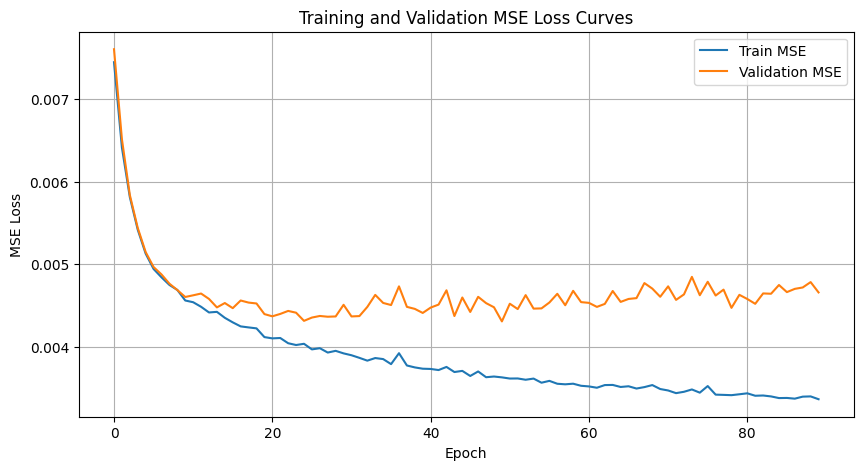

,model,type,train-mse,val-mse,test-mse,train-mre,val-mre,test-mre
0,(mSHRED): TR+cnn,(T.0): always-available stations only,0.004128,0.004438,0.006931,0.127817,0.135475,0.164078
1,(mSHRED): LSTM+cnn,(S.0): always-available stations only,0.004119,0.004407,0.007174,0.127691,0.134495,0.165759
2,(mSHRED): TR+cnn,(T.1.A): median imputation for missing sensors,0.003774,0.004191,0.006484,0.123139,0.131816,0.159573
3,(mSHRED): TR+cnn,(T.1.B): mean imputation for missing sensors,0.003955,0.004294,0.006661,0.126321,0.133619,0.161729
4,(mSHRED): TR+cnn,(T.1.C): last-value imputation for missing sen...,0.003910,0.004221,0.006563,0.125312,0.132687,0.160349
5,(mSHRED): GRUD+cnn,(T.2.A): GRUD,0.003932,0.004580,0.006809,0.126058,0.138078,0.163755
6,(mSHRED): Attn-GRUD+cnn,(T.2.B): Attn-GRUD,0.003910,0.004601,0.006780,0.125298,0.137999,0.163068
7,(mSHRED): TR+cnn,(T.3.A): masking,0.004019,0.004317,0.006623,0.127119,0.134015,0.161857
8,(mSHRED): TR+cnn,(T.3.B): masking x2 channels,0.004072,0.004391,0.006717,0.127659,0.136133,0.163249
9,(mSHRED): TR+cnn,(T.3.C): masking hidden space,0.003632,0.004309,0.006555,0.121541,0.133713,0.160359


In [38]:
# mSHRED TRAINING
model_args = dict(
    # Encoder
    encoder="transformer_hidden_mask", encoder_depth=ENCODER_DEPTH, input_size=nn_input_shape, n_heads=N_HEADS,
    dim_feedforward=DIM_FEEDFORWARD, hidden_size=HIDDEN_SIZE, input_length=LAGS,
    # Decoder
    decoder=DECODER, decoder_hidden_sizes=DECODER_HIDDEN_SIZES, output_size=nn_output_shape, dropout=DROPOUT, 
 )
mshred = mSHRED(args=model_args).to(device)

# Use cosine annealing LR schedule
train_errors, valid_errors = fit(
    mshred, train_dataset, val_dataset,
    optimizer=OPTIMIZER, lr=LEARNING_RATE, num_epochs=NUM_EPOCHS, patience=PATIENCE, verbose=VERBOSE_TRAIN,
    lr_scheduler=LR_SCHEDULER, scheduler_step_size=SCHEDULER_STEP_SIZE,
    masking_type=MASKING_TYPE,
 )

# PLOT TRAINING CURVES
plot_training_curves(train_errors, valid_errors)

# EVALUATION
test_error = evaluate_model(
    evaluate, mshred, train_dataset, val_dataset, test_dataset,
    model=f"(mSHRED): TR+{DECODER}", type="(T.3.C): masking hidden space", masking_type=MASKING_TYPE
 )

# Save errors to dataframe
ERRORS.append(test_error)
dataframe_errors = pd.DataFrame(ERRORS)
display(dataframe_errors)
dataframe_errors.to_csv("dataframe_errors.csv", index=False)

Saved plot: /home/matteo/Documents/Masked-SHRED/Notebooks/HYDRO/outputs/shred_(T.3.C)_masking_hidden_space.png


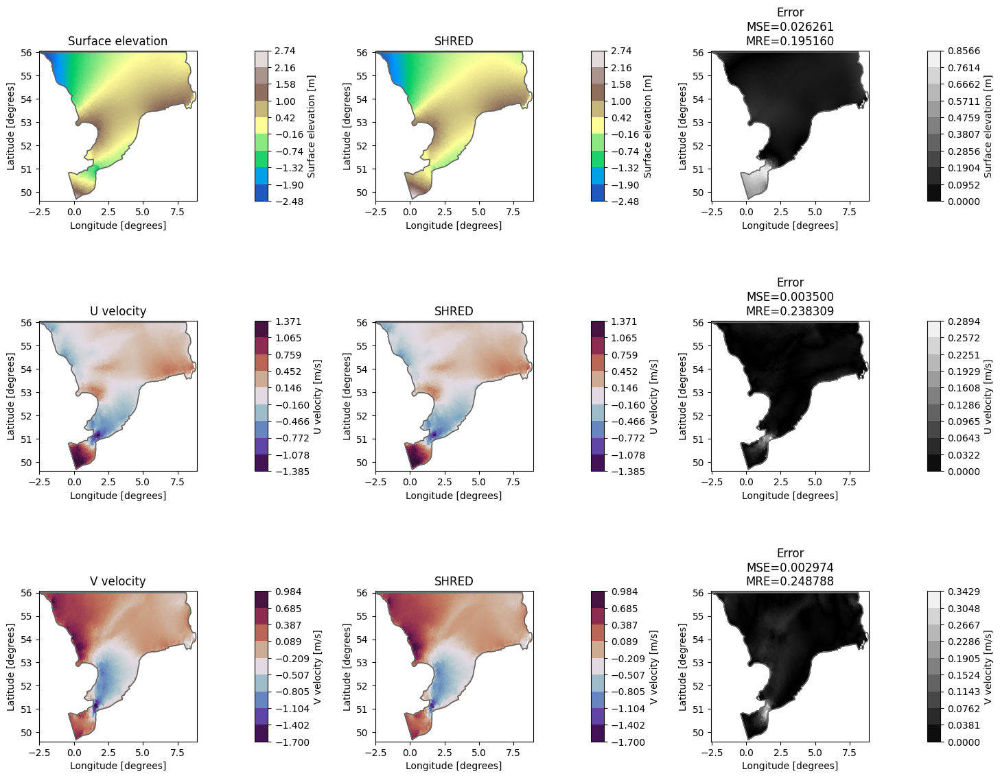

In [39]:
# mSHRED RECONSTRUCTION
engine = SHREDEngine(manager, mshred)
test_reconstruction = engine.sensor_to_reconstruction_dataset(test_dataset)
ds_r = align_ds(manager.test_indices, ds, permuted_indices, lenmonths, geom)
ds_shred, ds_error = plot_shred_reconstruction(test_reconstruction, ds_r, geom, title_suffix="(T.3.C)_masking_hidden_space")

del engine, test_reconstruction, ds_shred, ds_error, mshred, model_args, train_errors, valid_errors, test_error

## (T.3.D): Masking MHSA

Starting training...


Training:  47%|████▋     | 94/200 [09:12<10:23,  5.88s/it, Train Loss=0.00335, Val Loss=0.00465, Patience=39, Best Val Loss=0.00427, LR=5.39e-04]

Early stopping at epoch 95
Training completed with best validation loss: 0.0043


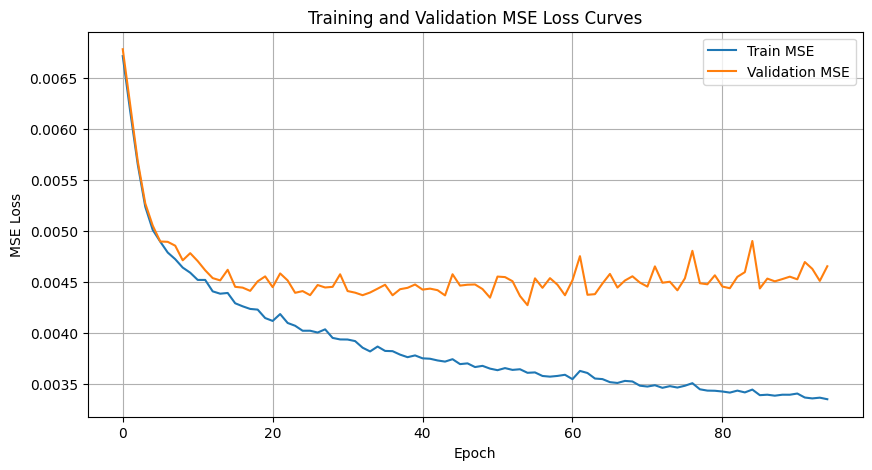

,model,type,train-mse,val-mse,test-mse,train-mre,val-mre,test-mre
0,(mSHRED): TR+cnn,(T.0): always-available stations only,0.004128,0.004438,0.006931,0.127817,0.135475,0.164078
1,(mSHRED): LSTM+cnn,(S.0): always-available stations only,0.004119,0.004407,0.007174,0.127691,0.134495,0.165759
2,(mSHRED): TR+cnn,(T.1.A): median imputation for missing sensors,0.003774,0.004191,0.006484,0.123139,0.131816,0.159573
3,(mSHRED): TR+cnn,(T.1.B): mean imputation for missing sensors,0.003955,0.004294,0.006661,0.126321,0.133619,0.161729
4,(mSHRED): TR+cnn,(T.1.C): last-value imputation for missing sen...,0.003910,0.004221,0.006563,0.125312,0.132687,0.160349
5,(mSHRED): GRUD+cnn,(T.2.A): GRUD,0.003932,0.004580,0.006809,0.126058,0.138078,0.163755
6,(mSHRED): Attn-GRUD+cnn,(T.2.B): Attn-GRUD,0.003910,0.004601,0.006780,0.125298,0.137999,0.163068
7,(mSHRED): TR+cnn,(T.3.A): masking,0.004019,0.004317,0.006623,0.127119,0.134015,0.161857
8,(mSHRED): TR+cnn,(T.3.B): masking x2 channels,0.004072,0.004391,0.006717,0.127659,0.136133,0.163249
9,(mSHRED): TR+cnn,(T.3.C): masking hidden space,0.003632,0.004309,0.006555,0.121541,0.133713,0.160359


In [40]:
# mSHRED TRAINING
model_args = dict(
    # Encoder
    encoder="transformer_attn_mask", encoder_depth=ENCODER_DEPTH, input_size=nn_input_shape, n_heads=N_HEADS,
    dim_feedforward=DIM_FEEDFORWARD, hidden_size=HIDDEN_SIZE, input_length=LAGS, double_channels=False,
    # Decoder
    decoder=DECODER, decoder_hidden_sizes=DECODER_HIDDEN_SIZES, output_size=nn_output_shape, dropout=DROPOUT, 
 )
mshred = mSHRED(args=model_args).to(device)

# Use cosine annealing LR schedule
train_errors, valid_errors = fit(
    mshred, train_dataset, val_dataset,
    optimizer=OPTIMIZER, lr=LEARNING_RATE, num_epochs=NUM_EPOCHS, patience=PATIENCE, verbose=VERBOSE_TRAIN,
    lr_scheduler=LR_SCHEDULER, scheduler_step_size=SCHEDULER_STEP_SIZE,
    masking_type=MASKING_TYPE,
 )

# PLOT TRAINING CURVES
plot_training_curves(train_errors, valid_errors)

# EVALUATION
test_error = evaluate_model(
    evaluate, mshred, train_dataset, val_dataset, test_dataset,
    model=f"(mSHRED): TR+{DECODER}", type="(T.3.D): masking MHSA", masking_type=MASKING_TYPE
 )

# Save errors to dataframe
ERRORS.append(test_error)
dataframe_errors = pd.DataFrame(ERRORS)
display(dataframe_errors)
dataframe_errors.to_csv("dataframe_errors.csv", index=False)

Saved plot: /home/matteo/Documents/Masked-SHRED/Notebooks/HYDRO/outputs/shred_(T.3.D)_masking_MHSA.png


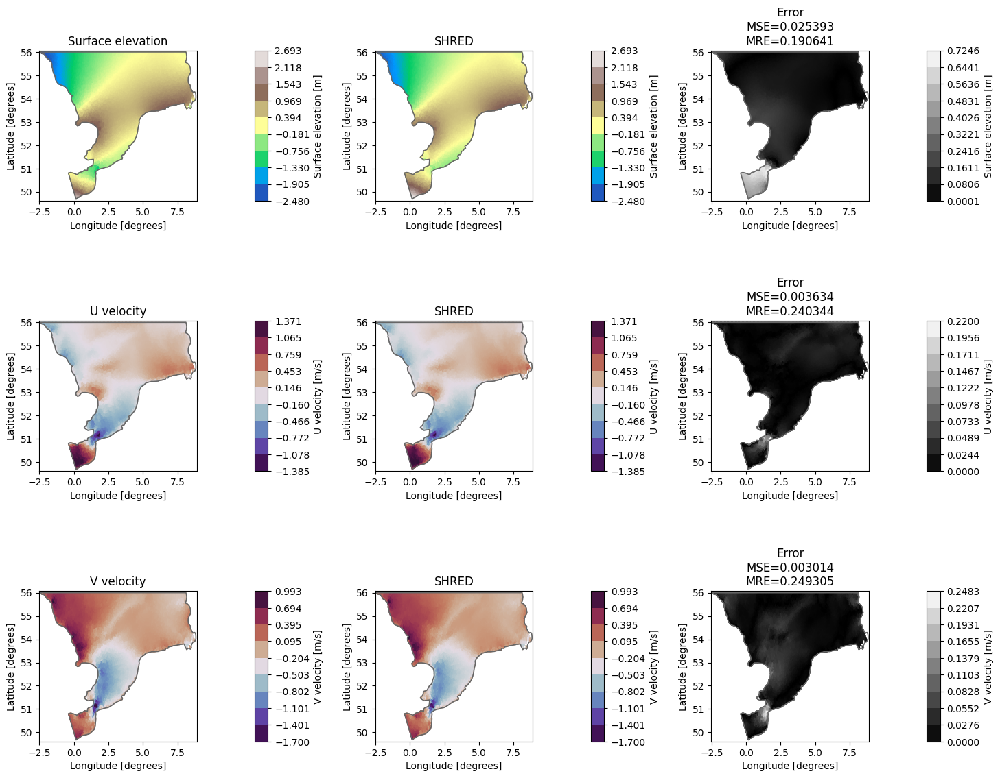

In [41]:
# mSHRED RECONSTRUCTION
engine = SHREDEngine(manager, mshred)
test_reconstruction = engine.sensor_to_reconstruction_dataset(test_dataset)
ds_r = align_ds(manager.test_indices, ds, permuted_indices, lenmonths, geom)
ds_shred, ds_error = plot_shred_reconstruction(test_reconstruction, ds_r, geom, title_suffix="(T.3.D)_masking_MHSA")

del engine, test_reconstruction, ds_shred, ds_error, mshred, model_args, train_errors, valid_errors, test_error

## (T.3.E): Masking x2 channels + MHSA

Starting training...


Training:  34%|███▎      | 67/200 [06:49<13:33,  6.12s/it, Train Loss=0.00343, Val Loss=0.00463, Patience=39, Best Val Loss=0.00431, LR=7.41e-04]

Early stopping at epoch 68
Training completed with best validation loss: 0.0043


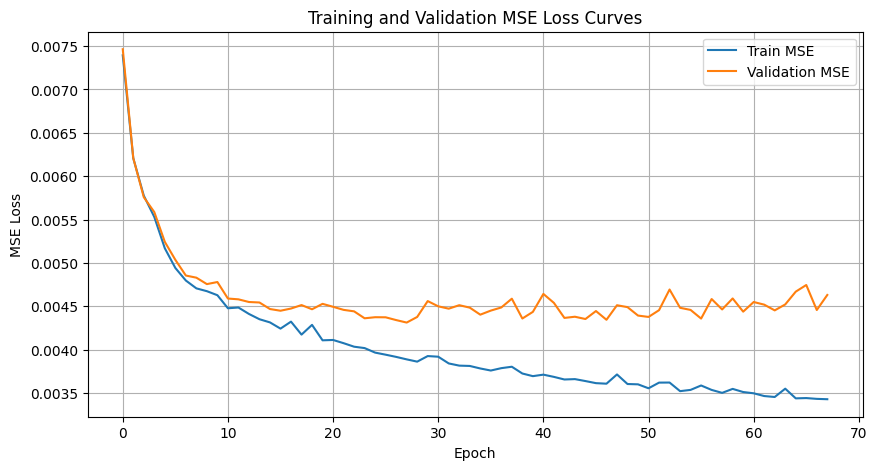

,model,type,train-mse,val-mse,test-mse,train-mre,val-mre,test-mre
0,(mSHRED): TR+cnn,(T.0): always-available stations only,0.004128,0.004438,0.006931,0.127817,0.135475,0.164078
1,(mSHRED): LSTM+cnn,(S.0): always-available stations only,0.004119,0.004407,0.007174,0.127691,0.134495,0.165759
2,(mSHRED): TR+cnn,(T.1.A): median imputation for missing sensors,0.003774,0.004191,0.006484,0.123139,0.131816,0.159573
3,(mSHRED): TR+cnn,(T.1.B): mean imputation for missing sensors,0.003955,0.004294,0.006661,0.126321,0.133619,0.161729
4,(mSHRED): TR+cnn,(T.1.C): last-value imputation for missing sen...,0.003910,0.004221,0.006563,0.125312,0.132687,0.160349
5,(mSHRED): GRUD+cnn,(T.2.A): GRUD,0.003932,0.004580,0.006809,0.126058,0.138078,0.163755
6,(mSHRED): Attn-GRUD+cnn,(T.2.B): Attn-GRUD,0.003910,0.004601,0.006780,0.125298,0.137999,0.163068
7,(mSHRED): TR+cnn,(T.3.A): masking,0.004019,0.004317,0.006623,0.127119,0.134015,0.161857
8,(mSHRED): TR+cnn,(T.3.B): masking x2 channels,0.004072,0.004391,0.006717,0.127659,0.136133,0.163249
9,(mSHRED): TR+cnn,(T.3.C): masking hidden space,0.003632,0.004309,0.006555,0.121541,0.133713,0.160359


In [42]:
# mSHRED TRAINING
model_args = dict(
    # Encoder
    encoder="transformer_attn_mask", encoder_depth=ENCODER_DEPTH, input_size=nn_input_shape, n_heads=N_HEADS,
    dim_feedforward=DIM_FEEDFORWARD, hidden_size=HIDDEN_SIZE, input_length=LAGS, double_channels=True,
    # Decoder
    decoder=DECODER, decoder_hidden_sizes=DECODER_HIDDEN_SIZES, output_size=nn_output_shape, dropout=DROPOUT, 
 )
mshred = mSHRED(args=model_args).to(device)

# Use cosine annealing LR schedule
train_errors, valid_errors = fit(
    mshred, train_dataset, val_dataset,
    optimizer=OPTIMIZER, lr=LEARNING_RATE, num_epochs=NUM_EPOCHS, patience=PATIENCE, verbose=VERBOSE_TRAIN,
    lr_scheduler=LR_SCHEDULER, scheduler_step_size=SCHEDULER_STEP_SIZE,
    masking_type=MASKING_TYPE,
 )

# PLOT TRAINING CURVES
plot_training_curves(train_errors, valid_errors)

# EVALUATION
test_error = evaluate_model(
    evaluate, mshred, train_dataset, val_dataset, test_dataset,
    model=f"(mSHRED): TR+{DECODER}", type="(T.3.E): masking x2 channels + MHSA", masking_type=MASKING_TYPE
 )

# Save errors to dataframe
ERRORS.append(test_error)
dataframe_errors = pd.DataFrame(ERRORS)
display(dataframe_errors)
dataframe_errors.to_csv("dataframe_errors.csv", index=False)

Saved plot: /home/matteo/Documents/Masked-SHRED/Notebooks/HYDRO/outputs/shred_(T.3.E)_masking_x2_channels_MHSA.png


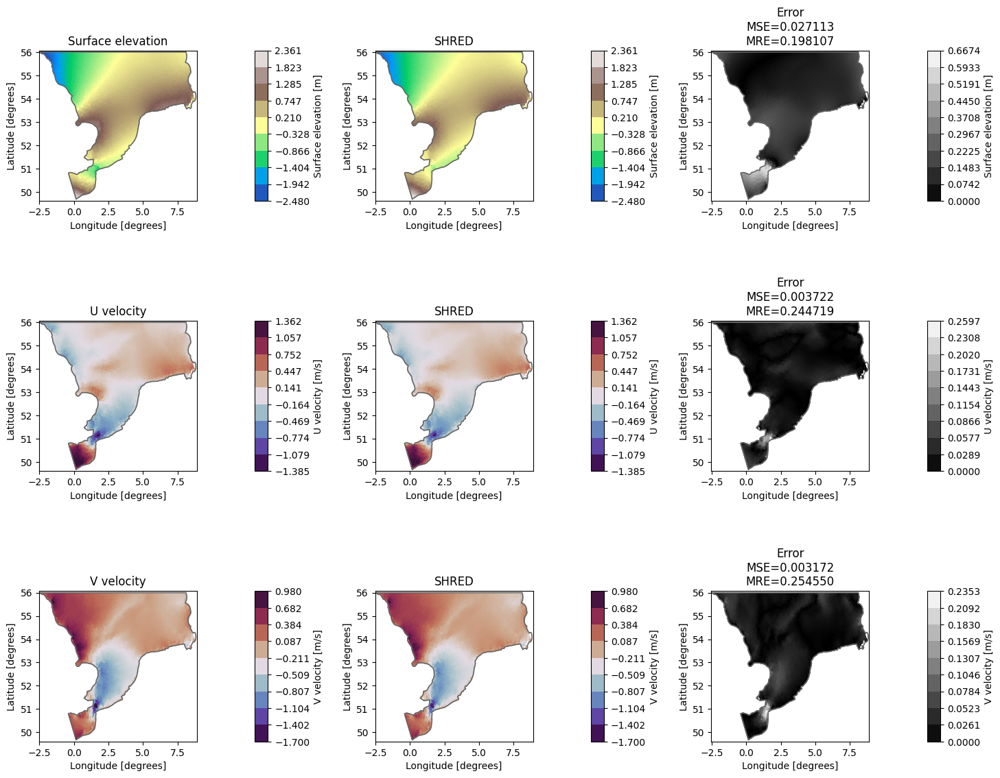

In [43]:
# mSHRED RECONSTRUCTION
engine = SHREDEngine(manager, mshred)
test_reconstruction = engine.sensor_to_reconstruction_dataset(test_dataset)
ds_r = align_ds(manager.test_indices, ds, permuted_indices, lenmonths, geom)
ds_shred, ds_error = plot_shred_reconstruction(test_reconstruction, ds_r, geom, title_suffix="(T.3.E)_masking_x2_channels_MHSA")

del engine, test_reconstruction, ds_shred, ds_error, mshred, model_args, train_errors, valid_errors, test_error

## (T.3.F): Masking MHSA learned

Starting training...


Training:  28%|██▊       | 56/200 [09:27<24:18, 10.13s/it, Train Loss=0.00346, Val Loss=0.00464, Patience=39, Best Val Loss=0.00439, LR=8.13e-04]

Early stopping at epoch 57
Training completed with best validation loss: 0.0044


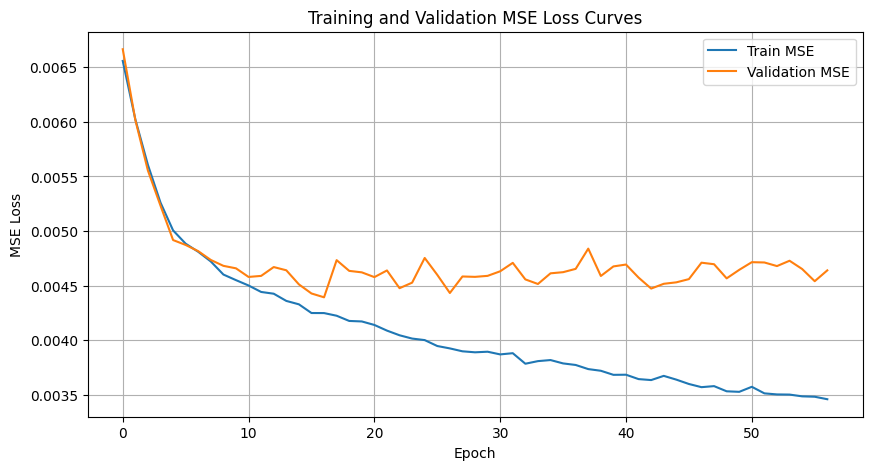

,model,type,train-mse,val-mse,test-mse,train-mre,val-mre,test-mre
0,(mSHRED): TR+cnn,(T.0): always-available stations only,0.004128,0.004438,0.006931,0.127817,0.135475,0.164078
1,(mSHRED): LSTM+cnn,(S.0): always-available stations only,0.004119,0.004407,0.007174,0.127691,0.134495,0.165759
2,(mSHRED): TR+cnn,(T.1.A): median imputation for missing sensors,0.003774,0.004191,0.006484,0.123139,0.131816,0.159573
3,(mSHRED): TR+cnn,(T.1.B): mean imputation for missing sensors,0.003955,0.004294,0.006661,0.126321,0.133619,0.161729
4,(mSHRED): TR+cnn,(T.1.C): last-value imputation for missing sen...,0.003910,0.004221,0.006563,0.125312,0.132687,0.160349
5,(mSHRED): GRUD+cnn,(T.2.A): GRUD,0.003932,0.004580,0.006809,0.126058,0.138078,0.163755
6,(mSHRED): Attn-GRUD+cnn,(T.2.B): Attn-GRUD,0.003910,0.004601,0.006780,0.125298,0.137999,0.163068
7,(mSHRED): TR+cnn,(T.3.A): masking,0.004019,0.004317,0.006623,0.127119,0.134015,0.161857
8,(mSHRED): TR+cnn,(T.3.B): masking x2 channels,0.004072,0.004391,0.006717,0.127659,0.136133,0.163249
9,(mSHRED): TR+cnn,(T.3.C): masking hidden space,0.003632,0.004309,0.006555,0.121541,0.133713,0.160359


In [44]:
# mSHRED TRAINING
model_args = dict(
    # Encoder
    encoder="transformer_learned_mask", encoder_depth=ENCODER_DEPTH, input_size=nn_input_shape, n_heads=N_HEADS,
    dim_feedforward=DIM_FEEDFORWARD, hidden_size=HIDDEN_SIZE, input_length=LAGS,
    # Decoder
    decoder=DECODER, decoder_hidden_sizes=DECODER_HIDDEN_SIZES, output_size=nn_output_shape, dropout=DROPOUT, 
 )
mshred = mSHRED(args=model_args).to(device)

# Use cosine annealing LR schedule
train_errors, valid_errors = fit(
    mshred, train_dataset, val_dataset,
    optimizer=OPTIMIZER, lr=LEARNING_RATE, num_epochs=NUM_EPOCHS, patience=PATIENCE, verbose=VERBOSE_TRAIN,
    lr_scheduler=LR_SCHEDULER, scheduler_step_size=SCHEDULER_STEP_SIZE,
    masking_type=MASKING_TYPE,
 )

# PLOT TRAINING CURVES
plot_training_curves(train_errors, valid_errors)

# EVALUATION
test_error = evaluate_model(
    evaluate, mshred, train_dataset, val_dataset, test_dataset,
    model=f"(mSHRED): TR+{DECODER}", type="(T.3.F): masking MHSA learned", masking_type=MASKING_TYPE
 )

# Save errors to dataframe
ERRORS.append(test_error)
dataframe_errors = pd.DataFrame(ERRORS)
display(dataframe_errors)
dataframe_errors.to_csv("dataframe_errors.csv", index=False)

Saved plot: /home/matteo/Documents/Masked-SHRED/Notebooks/HYDRO/outputs/shred_(T.3.F)_masking_MHSA_learned.png


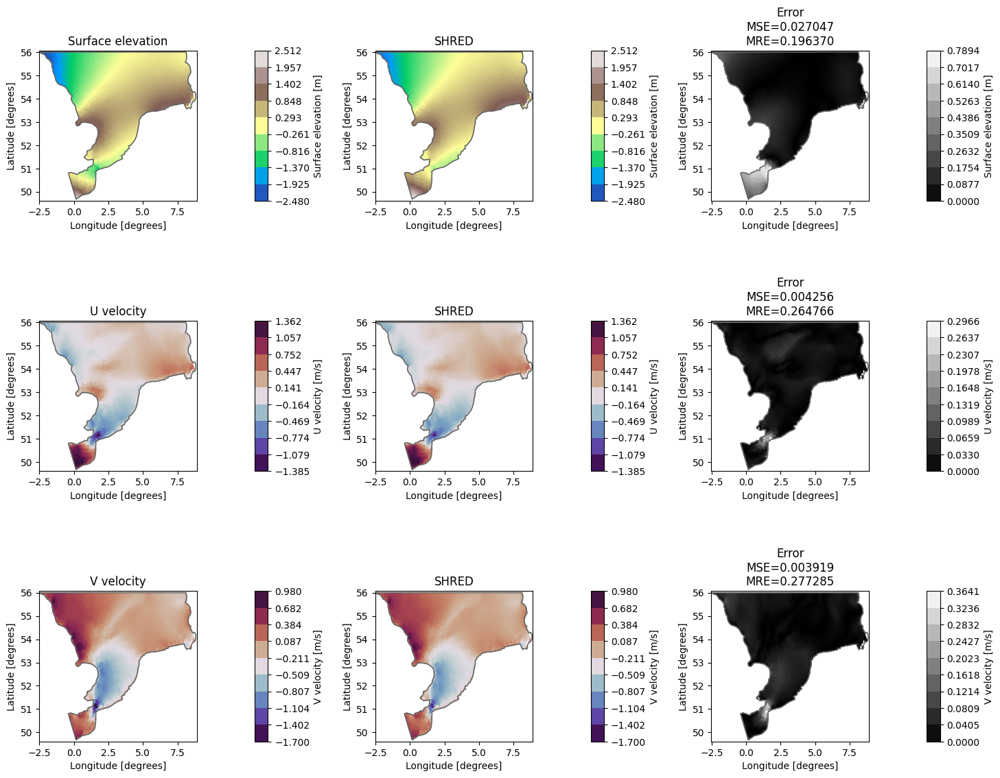

In [45]:
# mSHRED RECONSTRUCTION
engine = SHREDEngine(manager, mshred)
test_reconstruction = engine.sensor_to_reconstruction_dataset(test_dataset)
ds_r = align_ds(manager.test_indices, ds, permuted_indices, lenmonths, geom)
ds_shred, ds_error = plot_shred_reconstruction(test_reconstruction, ds_r, geom, title_suffix="(T.3.F)_masking_MHSA_learned")

del engine, test_reconstruction, ds_shred, ds_error, mshred, model_args, train_errors, valid_errors, test_error

## (T.3.G): Masking x2 channels + MHSA learned

Starting training...


Training:  32%|███▏      | 63/200 [11:32<25:06, 10.99s/it, Train Loss=0.00338, Val Loss=0.00474, Patience=39, Best Val Loss=0.00435, LR=7.68e-04]

Early stopping at epoch 64
Training completed with best validation loss: 0.0044


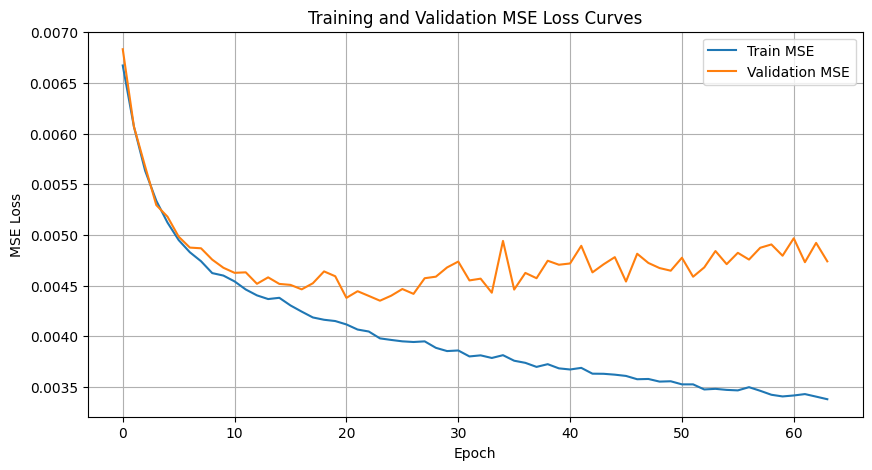

,model,type,train-mse,val-mse,test-mse,train-mre,val-mre,test-mre
0,(mSHRED): TR+cnn,(T.0): always-available stations only,0.004128,0.004438,0.006931,0.127817,0.135475,0.164078
1,(mSHRED): LSTM+cnn,(S.0): always-available stations only,0.004119,0.004407,0.007174,0.127691,0.134495,0.165759
2,(mSHRED): TR+cnn,(T.1.A): median imputation for missing sensors,0.003774,0.004191,0.006484,0.123139,0.131816,0.159573
3,(mSHRED): TR+cnn,(T.1.B): mean imputation for missing sensors,0.003955,0.004294,0.006661,0.126321,0.133619,0.161729
4,(mSHRED): TR+cnn,(T.1.C): last-value imputation for missing sen...,0.003910,0.004221,0.006563,0.125312,0.132687,0.160349
5,(mSHRED): GRUD+cnn,(T.2.A): GRUD,0.003932,0.004580,0.006809,0.126058,0.138078,0.163755
6,(mSHRED): Attn-GRUD+cnn,(T.2.B): Attn-GRUD,0.003910,0.004601,0.006780,0.125298,0.137999,0.163068
7,(mSHRED): TR+cnn,(T.3.A): masking,0.004019,0.004317,0.006623,0.127119,0.134015,0.161857
8,(mSHRED): TR+cnn,(T.3.B): masking x2 channels,0.004072,0.004391,0.006717,0.127659,0.136133,0.163249
9,(mSHRED): TR+cnn,(T.3.C): masking hidden space,0.003632,0.004309,0.006555,0.121541,0.133713,0.160359


In [46]:
# mSHRED TRAINING
model_args = dict(
    # Encoder
    encoder="transformer_learned_mask", encoder_depth=ENCODER_DEPTH, input_size=nn_input_shape, n_heads=N_HEADS,
    dim_feedforward=DIM_FEEDFORWARD, hidden_size=HIDDEN_SIZE, input_length=LAGS, double_channels=True,
    # Decoder
    decoder=DECODER, decoder_hidden_sizes=DECODER_HIDDEN_SIZES, output_size=nn_output_shape, dropout=DROPOUT, 
 )
mshred = mSHRED(args=model_args).to(device)

# Use cosine annealing LR schedule
train_errors, valid_errors = fit(
    mshred, train_dataset, val_dataset,
    optimizer=OPTIMIZER, lr=LEARNING_RATE, num_epochs=NUM_EPOCHS, patience=PATIENCE, verbose=VERBOSE_TRAIN,
    lr_scheduler=LR_SCHEDULER, scheduler_step_size=SCHEDULER_STEP_SIZE,
    masking_type=MASKING_TYPE,
 )

# PLOT TRAINING CURVES
plot_training_curves(train_errors, valid_errors)

# EVALUATION
test_error = evaluate_model(
    evaluate, mshred, train_dataset, val_dataset, test_dataset,
    model=f"(mSHRED): TR+{DECODER}", type="(T.3.G): masking x2 channels + MHSA learned", masking_type=MASKING_TYPE
 )

# Save errors to dataframe
ERRORS.append(test_error)
dataframe_errors = pd.DataFrame(ERRORS)
display(dataframe_errors)
dataframe_errors.to_csv("dataframe_errors.csv", index=False)

Saved plot: /home/matteo/Documents/Masked-SHRED/Notebooks/HYDRO/outputs/shred_(T.3.G)_masking_x2_channels_MHSA_learned.png


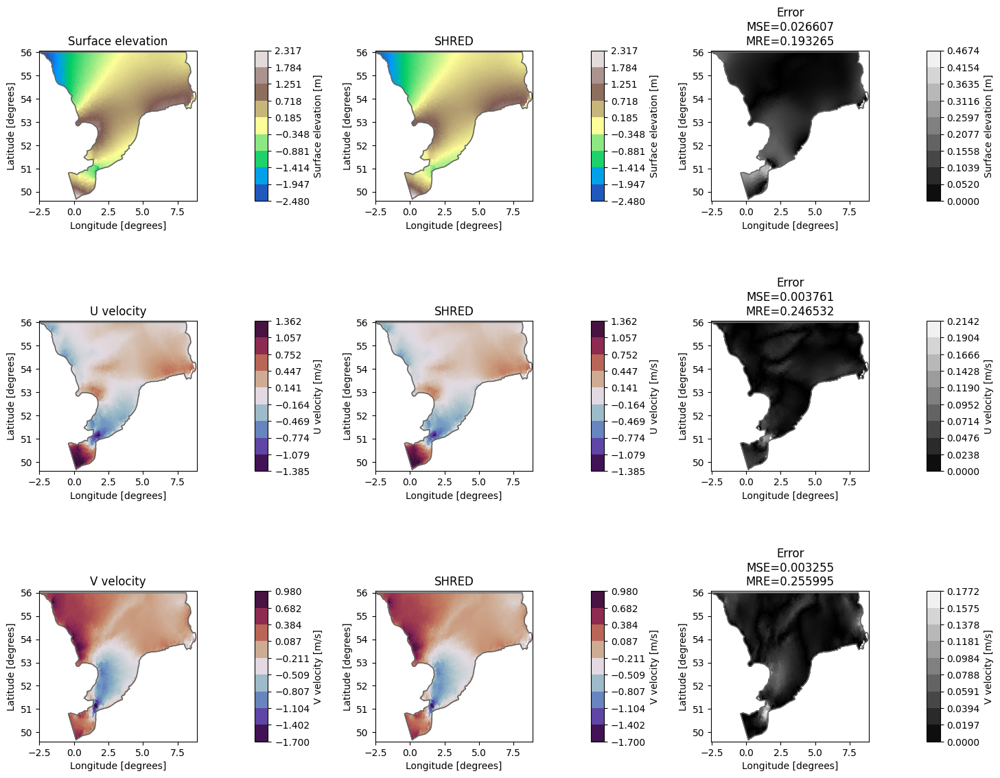

In [47]:
# mSHRED RECONSTRUCTION
engine = SHREDEngine(manager, mshred)
test_reconstruction = engine.sensor_to_reconstruction_dataset(test_dataset)
ds_r = align_ds(manager.test_indices, ds, permuted_indices, lenmonths, geom)
ds_shred, ds_error = plot_shred_reconstruction(test_reconstruction, ds_r, geom, title_suffix="(T.3.G)_masking_x2_channels_MHSA_learned")

del engine, test_reconstruction, ds_shred, ds_error, mshred, manager, train_dataset, val_dataset, test_dataset, model_args, train_errors, valid_errors, test_error, nn_input_shape, nn_output_shape

## Results

In [48]:
dataframe_errors = pd.read_csv("dataframe_errors.csv")  # reload to ensure clean data
display(dataframe_errors)
dataframe_errors.to_csv("dataframe_errors.csv", index=False)

,model,type,train-mse,val-mse,test-mse,train-mre,val-mre,test-mre
0,(mSHRED): TR+cnn,(T.0): always-available stations only,0.004128,0.004438,0.006931,0.127817,0.135475,0.164078
1,(mSHRED): LSTM+cnn,(S.0): always-available stations only,0.004119,0.004407,0.007174,0.127691,0.134495,0.165759
2,(mSHRED): TR+cnn,(T.1.A): median imputation for missing sensors,0.003774,0.004191,0.006484,0.123139,0.131816,0.159573
3,(mSHRED): TR+cnn,(T.1.B): mean imputation for missing sensors,0.003955,0.004294,0.006661,0.126321,0.133619,0.161729
4,(mSHRED): TR+cnn,(T.1.C): last-value imputation for missing sen...,0.003910,0.004221,0.006563,0.125312,0.132687,0.160349
5,(mSHRED): GRUD+cnn,(T.2.A): GRUD,0.003932,0.004580,0.006809,0.126058,0.138078,0.163755
6,(mSHRED): Attn-GRUD+cnn,(T.2.B): Attn-GRUD,0.003910,0.004601,0.006780,0.125298,0.137999,0.163068
7,(mSHRED): TR+cnn,(T.3.A): masking,0.004019,0.004317,0.006623,0.127119,0.134015,0.161857
8,(mSHRED): TR+cnn,(T.3.B): masking x2 channels,0.004072,0.004391,0.006717,0.127659,0.136133,0.163249
9,(mSHRED): TR+cnn,(T.3.C): masking hidden space,0.003632,0.004309,0.006555,0.121541,0.133713,0.160359


In [49]:
# order dataframe by test-mre
print("\nFinal comparison of all models, ordered by test MRE:")
dataframe_errors = dataframe_errors.sort_values(by="test-mre")
display(dataframe_errors)


Final comparison of all models, ordered by test MRE:


,model,type,train-mse,val-mse,test-mse,train-mre,val-mre,test-mre
2,(mSHRED): TR+cnn,(T.1.A): median imputation for missing sensors,0.003774,0.004191,0.006484,0.123139,0.131816,0.159573
10,(mSHRED): TR+cnn,(T.3.D): masking MHSA,0.003606,0.004269,0.006536,0.120916,0.133186,0.159613
4,(mSHRED): TR+cnn,(T.1.C): last-value imputation for missing sen...,0.003910,0.004221,0.006563,0.125312,0.132687,0.160349
9,(mSHRED): TR+cnn,(T.3.C): masking hidden space,0.003632,0.004309,0.006555,0.121541,0.133713,0.160359
11,(mSHRED): TR+cnn,(T.3.E): masking x2 channels + MHSA,0.003889,0.004313,0.006566,0.125107,0.134546,0.160395
13,(mSHRED): TR+cnn,(T.3.G): masking x2 channels + MHSA learned,0.003980,0.004351,0.006578,0.126276,0.134434,0.160652
3,(mSHRED): TR+cnn,(T.1.B): mean imputation for missing sensors,0.003955,0.004294,0.006661,0.126321,0.133619,0.161729
7,(mSHRED): TR+cnn,(T.3.A): masking,0.004019,0.004317,0.006623,0.127119,0.134015,0.161857
6,(mSHRED): Attn-GRUD+cnn,(T.2.B): Attn-GRUD,0.003910,0.004601,0.006780,0.125298,0.137999,0.163068
8,(mSHRED): TR+cnn,(T.3.B): masking x2 channels,0.004072,0.004391,0.006717,0.127659,0.136133,0.163249


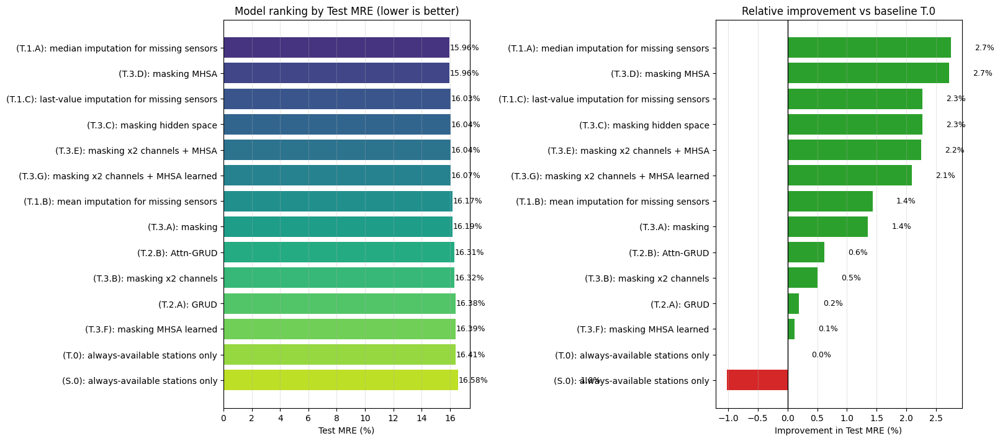

In [50]:
# Meaningful summary plot: ranking + improvement vs baseline
df_plot = dataframe_errors.sort_values("test-mre").reset_index(drop=True)

# Baseline = T.0 (only available sensors)
baseline_mask = df_plot["type"].str.contains("T.0", regex=False)
baseline_test_mre = df_plot.loc[baseline_mask, "test-mre"].iloc[0] if baseline_mask.any() else df_plot["test-mre"].max()

# Keep raw values for ratio math, but plot MRE on a 0-100% scale
df_plot["test-mre_%"] = 100 * df_plot["test-mre"]
df_plot["improvement_vs_T0_%"] = 100 * (baseline_test_mre - df_plot["test-mre"]) / baseline_test_mre

fig, axes = plt.subplots(1, 2, figsize=(16, 7), constrained_layout=True)

# --- Left: Test MRE ranking (%) ---
colors = plt.cm.viridis(np.linspace(0.15, 0.9, len(df_plot)))
axes[0].barh(df_plot["type"], df_plot["test-mre_%"], color=colors)
axes[0].invert_yaxis()
axes[0].set_title("Model ranking by Test MRE (lower is better)")
axes[0].set_xlabel("Test MRE (%)")
axes[0].grid(axis="x", alpha=0.3)

for i, v in enumerate(df_plot["test-mre_%"]):
    axes[0].text(v + 0.03, i, f"{v:.2f}%", va="center", fontsize=9)

# --- Right: Improvement vs baseline (T.0) ---
imp_colors = ["tab:green" if x >= 0 else "tab:red" for x in df_plot["improvement_vs_T0_%"]]
axes[1].barh(df_plot["type"], df_plot["improvement_vs_T0_%"], color=imp_colors)
axes[1].invert_yaxis()
axes[1].axvline(0, color="black", linewidth=1)
axes[1].set_title("Relative improvement vs baseline T.0")
axes[1].set_xlabel("Improvement in Test MRE (%)")
axes[1].grid(axis="x", alpha=0.3)

for i, v in enumerate(df_plot["improvement_vs_T0_%"]):
    axes[1].text(v + (0.4 if v >= 0 else -2.5), i, f"{v:.1f}%", va="center", fontsize=9)

plt.show()

## Run 1: lag 48

permutation indices: [ 8 16  0 18 11  9 13  1 21  5  2 12 15  3  4 22 17 20 23  7 10 14 19  6]

In [51]:
ERRORS = []

# DataManager
LAGS = 48               # number of past time steps to use as input for the model (e.g., 48 for 24 hours of data at 30-minute intervals)

TRAIN_SIZE = 0.8        # percentage of data used for training 
VAL_SIZE = 0.1          # percentage of data used for validation
TEST_SIZE = 0.1         # percentage of data used for testing

COMPRESS_H = 12         # modes kept for H (surface elevation)
COMPRESS_U = 40         # modes kept for U (U velocity)
COMPRESS_V = 68         # modes kept for V (V velocity)

# Training
OPTIMIZER = "AdamW"     # optimizer to use
LEARNING_RATE = 1e-3    # learning rate for training
NUM_EPOCHS = 200        # maximum number of epochs for training
LR_SCHEDULER = "CosineAnnealingLR"      # learning rate scheduler to use
SCHEDULER_STEP_SIZE = NUM_EPOCHS        # step size for learning rate scheduler (if applicable)

BATCH_SIZE = 32         # batch size for training
PATIENCE = 40           # number of epochs with no improvement on validation loss before stopping training
VERBOSE_TRAIN = True

# Architecture
ENCODER_DEPTH = 2              # number of encoder layers
HIDDEN_SIZE = 32                # hidden size for encoder and decoder layers
N_HEADS = 4                     # number of attention heads (if using a transformer-based architecture)
DIM_FEEDFORWARD = 48            # dimension of feedforward network in transformer (if using a transformer-based architecture)
DECODER = "cnn"                 # type of decoder to use (mpl or cnn)   
DECODER_HIDDEN_SIZES = [64]     # hidden sizes for decoder layers 
DROPOUT = 0.0                   # dropout rate for encoder and decoder layers
MASKING_TYPE = "mask_data"      # type of masking to apply to inputs during training (mask_data, mask_data_random, etc.)

<div>
<style scoped>
    .dataframe tbody tr th:only-of-type {
        vertical-align: middle;
    }

    .dataframe tbody tr th {
        vertical-align: top;
    }

    .dataframe thead th {
        text-align: right;
    }
</style>
<table border="1" class="dataframe">
  <thead>
    <tr style="text-align: right;">
      <th></th>
      <th>model</th>
      <th>type</th>
      <th>train-mse</th>
      <th>val-mse</th>
      <th>test-mse</th>
      <th>train-mre</th>
      <th>val-mre</th>
      <th>test-mre</th>
    </tr>
  </thead>
  <tbody>
    <tr>
      <th>4</th>
      <td>(mSHRED): TR+cnn</td>
      <td>(T.1.C): last-value imputation for missing sen...</td>
      <td>0.003805</td>
      <td>0.005356</td>
      <td>0.003226</td>
      <td>0.124878</td>
      <td>0.136314</td>
      <td>0.117317</td>
    </tr>
    <tr>
      <th>11</th>
      <td>(mSHRED): TR+cnn</td>
      <td>(T.3.E): masking x2 channels + MHSA</td>
      <td>0.003924</td>
      <td>0.005364</td>
      <td>0.003263</td>
      <td>0.126488</td>
      <td>0.136571</td>
      <td>0.117916</td>
    </tr>
    <tr>
      <th>8</th>
      <td>(mSHRED): TR+cnn</td>
      <td>(T.3.B): masking x2 channels</td>
      <td>0.003923</td>
      <td>0.005287</td>
      <td>0.003286</td>
      <td>0.126295</td>
      <td>0.136148</td>
      <td>0.118486</td>
    </tr>
    <tr>
      <th>7</th>
      <td>(mSHRED): TR+cnn</td>
      <td>(T.3.A): masking</td>
      <td>0.003897</td>
      <td>0.005295</td>
      <td>0.003297</td>
      <td>0.126042</td>
      <td>0.135688</td>
      <td>0.118497</td>
    </tr>
    <tr>
      <th>13</th>
      <td>(mSHRED): TR+cnn</td>
      <td>(T.3.G): masking x2 channels + MHSA learned</td>
      <td>0.003889</td>
      <td>0.005304</td>
      <td>0.003314</td>
      <td>0.125845</td>
      <td>0.135812</td>
      <td>0.118948</td>
    </tr>
    <tr>
      <th>2</th>
      <td>(mSHRED): TR+cnn</td>
      <td>(T.1.A): median imputation for missing sensors</td>
      <td>0.004178</td>
      <td>0.005396</td>
      <td>0.003331</td>
      <td>0.129959</td>
      <td>0.137801</td>
      <td>0.119472</td>
    </tr>
    <tr>
      <th>9</th>
      <td>(mSHRED): TR+cnn</td>
      <td>(T.3.C): masking hidden space</td>
      <td>0.004036</td>
      <td>0.005245</td>
      <td>0.003353</td>
      <td>0.128253</td>
      <td>0.135165</td>
      <td>0.119748</td>
    </tr>
    <tr>
      <th>10</th>
      <td>(mSHRED): TR+cnn</td>
      <td>(T.3.D): masking MHSA</td>
      <td>0.003996</td>
      <td>0.005376</td>
      <td>0.003348</td>
      <td>0.127753</td>
      <td>0.137201</td>
      <td>0.119753</td>
    </tr>
    <tr>
      <th>3</th>
      <td>(mSHRED): TR+cnn</td>
      <td>(T.1.B): mean imputation for missing sensors</td>
      <td>0.004104</td>
      <td>0.005330</td>
      <td>0.003355</td>
      <td>0.128831</td>
      <td>0.136686</td>
      <td>0.119799</td>
    </tr>
    <tr>
      <th>12</th>
      <td>(mSHRED): TR+cnn</td>
      <td>(T.3.F): masking MHSA learned</td>
      <td>0.004023</td>
      <td>0.005336</td>
      <td>0.003349</td>
      <td>0.127621</td>
      <td>0.136558</td>
      <td>0.119824</td>
    </tr>
    <tr>
      <th>5</th>
      <td>(mSHRED): GRUD+cnn</td>
      <td>(T.2.A): GRUD</td>
      <td>0.004263</td>
      <td>0.005494</td>
      <td>0.003446</td>
      <td>0.131552</td>
      <td>0.139095</td>
      <td>0.121624</td>
    </tr>
    <tr>
      <th>1</th>
      <td>(mSHRED): LSTM+cnn</td>
      <td>(S.0): always-available stations only</td>
      <td>0.004331</td>
      <td>0.005629</td>
      <td>0.003482</td>
      <td>0.131667</td>
      <td>0.138526</td>
      <td>0.121786</td>
    </tr>
    <tr>
      <th>0</th>
      <td>(mSHRED): TR+cnn</td>
      <td>(T.0): always-available stations only</td>
      <td>0.004230</td>
      <td>0.005618</td>
      <td>0.003494</td>
      <td>0.130191</td>
      <td>0.138102</td>
      <td>0.121860</td>
    </tr>
    <tr>
      <th>6</th>
      <td>(mSHRED): Attn-GRUD+cnn</td>
      <td>(T.2.B): Attn-GRUD</td>
      <td>0.004289</td>
      <td>0.005402</td>
      <td>0.003491</td>
      <td>0.131941</td>
      <td>0.138916</td>
      <td>0.122422</td>
    </tr>
  </tbody>
</table>
</div>

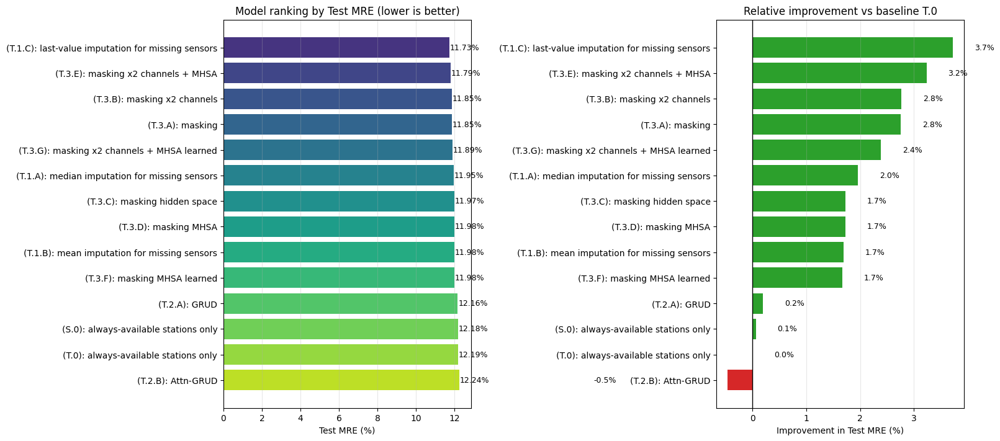

## Run 2: lag 48

permutation indices: [11 10 22 14 20  1 13 23 16  8  6 17  4  2  5 18  9  7 19  3  0 21 15 12]

In [ ]:
ERRORS = []

# DataManager
LAGS = 48               # number of past time steps to use as input for the model (e.g., 48 for 24 hours of data at 30-minute intervals)

TRAIN_SIZE = 0.8        # percentage of data used for training 
VAL_SIZE = 0.1          # percentage of data used for validation
TEST_SIZE = 0.1         # percentage of data used for testing

COMPRESS_H = 12         # modes kept for H (surface elevation)
COMPRESS_U = 40         # modes kept for U (U velocity)
COMPRESS_V = 68         # modes kept for V (V velocity)

# Training
OPTIMIZER = "AdamW"     # optimizer to use
LEARNING_RATE = 1e-3    # learning rate for training
NUM_EPOCHS = 200        # maximum number of epochs for training
LR_SCHEDULER = "CosineAnnealingLR"      # learning rate scheduler to use
SCHEDULER_STEP_SIZE = NUM_EPOCHS        # step size for learning rate scheduler (if applicable)

BATCH_SIZE = 32         # batch size for training
PATIENCE = 40           # number of epochs with no improvement on validation loss before stopping training
VERBOSE_TRAIN = True

# Architecture
ENCODER_DEPTH = 2              # number of encoder layers
HIDDEN_SIZE = 32                # hidden size for encoder and decoder layers
N_HEADS = 4                     # number of attention heads (if using a transformer-based architecture)
DIM_FEEDFORWARD = 48            # dimension of feedforward network in transformer (if using a transformer-based architecture)
DECODER = "cnn"                 # type of decoder to use (mpl or cnn)   
DECODER_HIDDEN_SIZES = [64]     # hidden sizes for decoder layers 
DROPOUT = 0.0                   # dropout rate for encoder and decoder layers
MASKING_TYPE = "mask_data"      # type of masking to apply to inputs during training (mask_data, mask_data_random, etc.)

<div>
<style scoped>
    .dataframe tbody tr th:only-of-type {
        vertical-align: middle;
    }

    .dataframe tbody tr th {
        vertical-align: top;
    }

    .dataframe thead th {
        text-align: right;
    }
</style>
<table border="1" class="dataframe">
  <thead>
    <tr style="text-align: right;">
      <th></th>
      <th>model</th>
      <th>type</th>
      <th>train-mse</th>
      <th>val-mse</th>
      <th>test-mse</th>
      <th>train-mre</th>
      <th>val-mre</th>
      <th>test-mre</th>
    </tr>
  </thead>
  <tbody>
    <tr>
      <th>2</th>
      <td>(mSHRED): TR+cnn</td>
      <td>(T.1.A): median imputation for missing sensors</td>
      <td>0.003774</td>
      <td>0.004191</td>
      <td>0.006484</td>
      <td>0.123139</td>
      <td>0.131816</td>
      <td>0.159573</td>
    </tr>
    <tr>
      <th>10</th>
      <td>(mSHRED): TR+cnn</td>
      <td>(T.3.D): masking MHSA</td>
      <td>0.003606</td>
      <td>0.004269</td>
      <td>0.006536</td>
      <td>0.120916</td>
      <td>0.133186</td>
      <td>0.159613</td>
    </tr>
    <tr>
      <th>4</th>
      <td>(mSHRED): TR+cnn</td>
      <td>(T.1.C): last-value imputation for missing sen...</td>
      <td>0.003910</td>
      <td>0.004221</td>
      <td>0.006563</td>
      <td>0.125312</td>
      <td>0.132687</td>
      <td>0.160349</td>
    </tr>
    <tr>
      <th>9</th>
      <td>(mSHRED): TR+cnn</td>
      <td>(T.3.C): masking hidden space</td>
      <td>0.003632</td>
      <td>0.004309</td>
      <td>0.006555</td>
      <td>0.121541</td>
      <td>0.133713</td>
      <td>0.160359</td>
    </tr>
    <tr>
      <th>11</th>
      <td>(mSHRED): TR+cnn</td>
      <td>(T.3.E): masking x2 channels + MHSA</td>
      <td>0.003889</td>
      <td>0.004313</td>
      <td>0.006566</td>
      <td>0.125107</td>
      <td>0.134546</td>
      <td>0.160395</td>
    </tr>
    <tr>
      <th>13</th>
      <td>(mSHRED): TR+cnn</td>
      <td>(T.3.G): masking x2 channels + MHSA learned</td>
      <td>0.003980</td>
      <td>0.004351</td>
      <td>0.006578</td>
      <td>0.126276</td>
      <td>0.134434</td>
      <td>0.160652</td>
    </tr>
    <tr>
      <th>3</th>
      <td>(mSHRED): TR+cnn</td>
      <td>(T.1.B): mean imputation for missing sensors</td>
      <td>0.003955</td>
      <td>0.004294</td>
      <td>0.006661</td>
      <td>0.126321</td>
      <td>0.133619</td>
      <td>0.161729</td>
    </tr>
    <tr>
      <th>7</th>
      <td>(mSHRED): TR+cnn</td>
      <td>(T.3.A): masking</td>
      <td>0.004019</td>
      <td>0.004317</td>
      <td>0.006623</td>
      <td>0.127119</td>
      <td>0.134015</td>
      <td>0.161857</td>
    </tr>
    <tr>
      <th>6</th>
      <td>(mSHRED): Attn-GRUD+cnn</td>
      <td>(T.2.B): Attn-GRUD</td>
      <td>0.003910</td>
      <td>0.004601</td>
      <td>0.006780</td>
      <td>0.125298</td>
      <td>0.137999</td>
      <td>0.163068</td>
    </tr>
    <tr>
      <th>8</th>
      <td>(mSHRED): TR+cnn</td>
      <td>(T.3.B): masking x2 channels</td>
      <td>0.004072</td>
      <td>0.004391</td>
      <td>0.006717</td>
      <td>0.127659</td>
      <td>0.136133</td>
      <td>0.163249</td>
    </tr>
    <tr>
      <th>5</th>
      <td>(mSHRED): GRUD+cnn</td>
      <td>(T.2.A): GRUD</td>
      <td>0.003932</td>
      <td>0.004580</td>
      <td>0.006809</td>
      <td>0.126058</td>
      <td>0.138078</td>
      <td>0.163755</td>
    </tr>
    <tr>
      <th>12</th>
      <td>(mSHRED): TR+cnn</td>
      <td>(T.3.F): masking MHSA learned</td>
      <td>0.004248</td>
      <td>0.004393</td>
      <td>0.006818</td>
      <td>0.130095</td>
      <td>0.135615</td>
      <td>0.163890</td>
    </tr>
    <tr>
      <th>0</th>
      <td>(mSHRED): TR+cnn</td>
      <td>(T.0): always-available stations only</td>
      <td>0.004128</td>
      <td>0.004438</td>
      <td>0.006931</td>
      <td>0.127817</td>
      <td>0.135475</td>
      <td>0.164078</td>
    </tr>
    <tr>
      <th>1</th>
      <td>(mSHRED): LSTM+cnn</td>
      <td>(S.0): always-available stations only</td>
      <td>0.004119</td>
      <td>0.004407</td>
      <td>0.007174</td>
      <td>0.127691</td>
      <td>0.134495</td>
      <td>0.165759</td>
    </tr>
  </tbody>
</table>
</div>

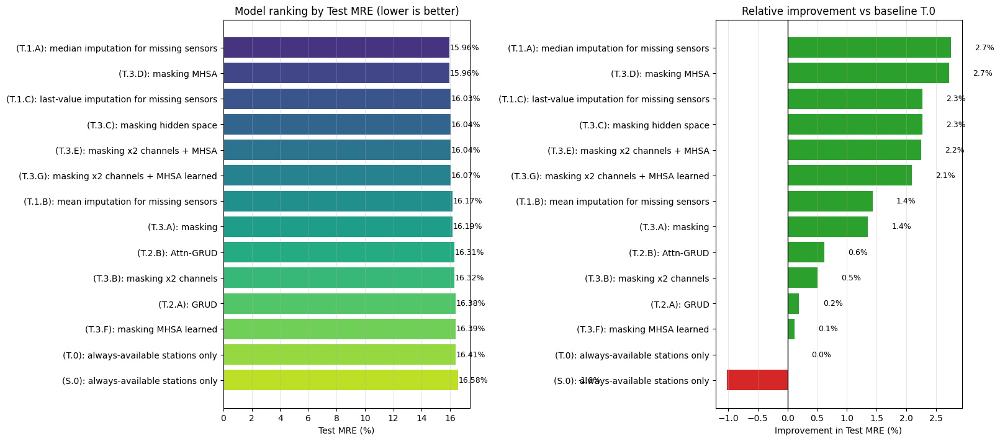